# MUMDMC2025 — Mineral Image Classification

**Reproduction and evaluation:** Decision Tree, KNN, cross-validation, hyperparameter tuning, error analysis, and CNN transfer learning.

## Project overview

**Reference:** B. G. Amer et al., *A Photomicrographic Dataset of Rocks for the Accurate Classification of Minerals*, *Scientific Data* (2025). DOI: https://doi.org/10.1038/s41597-025-05879-9

**Goal.** Reproduce the paper's Decision Tree and KNN classification methodology on the available data, compare image resolutions, and evaluate the results through additional experiments and CNN transfer learning.

**Dataset.** The accessible subset contains **583 images**, **five mineral classes**, and **eight acquisition folders**, rather than the 2,500 images described in the paper. This is a **partial reproduction**.

**Data splits.** Experiments 1–4 use a stratified **466 train / 117 test** split. Experiment 5 uses the same test set, with **396 train / 70 validation** for CNN training. The evaluation is **image-level**; it does not establish performance on independent unseen crystals.

**Reproducibility.** Run all cells from top to bottom in Google Colab, preferably with a GPU for Experiment 5. All random splits use seed 42; the CNN also configures PyTorch seeds. Model dependencies are listed in `requirements.txt` in the project package. Results are saved to `/content/outputs/`, and CNN weights to `/content/models/`. Internet access is needed to download the dataset and pretrained CNN weights.

**Data limitation.** Multiple rotation views from the same acquisition folder appear in both training and test sets. Folder identity is not a verified physical-crystal ID. The metadata workbook describes a different-sized dataset; repeated file names in the 583-image archive prevent unambiguous specimen identification.

The notebook includes saved outputs from an earlier Colab run. Re-running the notebook regenerates the experiments.

## Setup — environment and data

Install `gdown` in Colab. The remaining libraries are provided by a standard Colab environment or can be installed from the project's `requirements.txt`. Keep the following imports in one place to avoid repeated imports later in the notebook.

In [1]:
!pip -q install gdown

### Imports and library versions

All imports are centralized here, along with the plotting settings and a compact library-version report for reproducibility.

In [2]:
import copy
import os
import random
import time
import warnings
import zipfile
from collections import Counter
from importlib.metadata import version
from pathlib import Path

import cv2
import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from PIL import Image
from scipy.special import softmax
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, auc, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.tree import DecisionTreeClassifier
from torch.utils.data import DataLoader, Dataset
from torchvision import models as torchvision_models, transforms

warnings.filterwarnings("ignore")
plt.style.use("default")
sns.set_palette("husl")

print("Library versions:", {name: version(name) for name in
                            ("numpy", "pandas", "scikit-learn", "torch", "torchvision", "gdown")})

Library versions: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'gdown': '5.2.2'}


### Download the dataset

Download and extract the public MUMDMC2025 subset from Google Drive. All later cells use `dataset_path`.

In [3]:
# Download the public dataset
file_id = "1cq-YGOLOZfIrq3T1Nxv_VXJC0aQBR6fh"

gdown.download(
    id=file_id,
    output="/content/MUMDMC2025_DataSet.zip",
    quiet=False
)

# Extract the images
with zipfile.ZipFile("/content/MUMDMC2025_DataSet.zip") as zip_file:
    zip_file.extractall("/content")

# Location of cropped images
dataset_path = "/content/MUMDMC2025_DataSet/Cropped_Images"

print("Dataset loaded:", dataset_path)


Downloading...
From: https://drive.google.com/uc?id=1cq-YGOLOZfIrq3T1Nxv_VXJC0aQBR6fh
To: /content/MUMDMC2025_DataSet.zip
100%|██████████| 18.8M/18.8M [00:00<00:00, 47.2MB/s]


Dataset loaded: /content/MUMDMC2025_DataSet/Cropped_Images


## Dataset audit — image counts and acquisition groups

Before fitting a model, count images per class and per acquisition folder. We also check whether the **80/20 image-level split** places photographs from the same folder in both training and testing. A folder is treated as an image acquisition group, **not** as a verified unique crystal.

In [4]:
root = Path(dataset_path)
image_files = sorted(p for p in root.rglob("*")
                     if p.suffix.lower() in (".jpg", ".jpeg", ".png"))
labels = [p.relative_to(root).parts[0] for p in image_files]
groups = [str(p.parent.relative_to(root)) for p in image_files]

print("Total images:", len(image_files))
for mineral in sorted(set(labels)):
    counts = Counter(groups[i] for i in range(len(image_files)) if labels[i] == mineral)
    print(f"{mineral}: {sum(counts.values())} images, {len(counts)} series")
    for group, count in sorted(counts.items()):
        print(f"  {group}: {count}")

train_idx, test_idx = train_test_split(
    range(len(image_files)), test_size=0.2, random_state=42, stratify=labels
)
train_groups = {groups[i] for i in train_idx}
shared = sum(groups[i] in train_groups for i in test_idx)

print(f"\nTest images from series also present in training: {shared}/{len(test_idx)}")

Total images: 583
Biotite: 147 images, 2 series
  Biotite/CN/1: 72
  Biotite/CN/2: 75
Hornblende: 73 images, 1 series
  Hornblende/CN: 73
Plagioclase: 146 images, 2 series
  Plagioclase/CN/1: 73
  Plagioclase/CN/2: 73
Potassium_Feldspar: 73 images, 1 series
  Potassium_Feldspar/CN: 73
Quartz: 144 images, 2 series
  Quartz/CN/1: 72
  Quartz/CN/2: 72

Test images from series also present in training: 117/117


## Experiment 1 — Baseline: Decision Tree and KNN

**Objective.** Reproduce the classification approach described in the reference paper using our available image subset.

**Method.** Load five mineral classes, compare the original cropped images (standardized to a common size, **224×224** for this subset) with **150×150** resized images, flatten normalized RGB pixels into feature vectors, and use a stratified 80/20 train/test split (`random_state=42`). Train a Decision Tree (`random_state=42`) and KNN (`k=5`), then report accuracy, precision, recall, F1, timing, confusion matrices, and ROC curves.

This is our baseline implementation of the paper's methodology, adapted for the available files. The `RockClassificationPipeline` class organizes the original sequence of data preparation, training, evaluation, and result saving; the model settings and computations remain unchanged.

### Baseline pipeline

The class below defines image loading, feature extraction, model fitting, evaluation, and saved results. The following cell runs this pipeline using the extracted dataset.

In [5]:
class RockClassificationPipeline:
    def __init__(self, dataset_path):
        self.dataset_path = dataset_path
        self.images_original = []
        self.images_resized = []
        self.labels = []
        self.class_names = []
        self.label_encoder = LabelEncoder()
        self.scaler = StandardScaler()
        self.results = {}
        self.metadata = []
        self.common_size = None  # Store the common size for original images

    def download_and_setup(self):
        """Download and setup the dataset"""
        print(" Setting up dataset...")

        # Create output directories
        os.makedirs('/content/dataset', exist_ok=True)
        os.makedirs('/content/outputs', exist_ok=True)
        os.makedirs('/content/models', exist_ok=True)

        # Use the downloaded dataset
        dataset_source = self.dataset_path

        if os.path.exists(dataset_source):
            print(f" Found dataset at: {dataset_source}")
            print(f" Setting up dataset directory structure...")
            # Read images from the extracted folder
            self.dataset_dir = dataset_source
        else:
            print(f" Dataset not found at: {dataset_source}")
            print("Please ensure your dataset path is correct")
            return False

        print(" Dataset setup completed!")
        return True

    def load_images_and_labels(self):
        """Load images and extract labels"""
        print(" Loading images and extracting labels...")

        dataset_dir = self.dataset_dir

        if not os.path.exists(dataset_dir):
            print(f" Dataset directory not found: {dataset_dir}")
            return

        # Read mineral folders
        class_folders = [f for f in os.listdir(dataset_dir)
                        if os.path.isdir(os.path.join(dataset_dir, f))]
        self.class_names = sorted(class_folders)

        print(f" Found {len(self.class_names)} classes: {self.class_names}")

        for class_name in self.class_names:
            class_path = os.path.join(dataset_dir, class_name)
            image_files = []
            for folder, _, files in os.walk(class_path):
                for file in files:
                    if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff')):
                        image_files.append(os.path.join(folder, file))

            print(f"  Loading {len(image_files)} images from {class_name}...")

            for img_path in sorted(image_files):
                img_file = os.path.basename(img_path)

                try:
                    # Read an image
                    img_original = cv2.imread(img_path)
                    if img_original is not None:
                        img_original = cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB)

                        # Keep the original crop
                        self.images_original.append(img_original)

                        # Resize to 150x150
                        img_resized = cv2.resize(img_original, (150, 150))
                        self.images_resized.append(img_resized)

                        # Store the class label
                        self.labels.append(class_name)

                        # Store image metadata
                        img_shape = img_original.shape
                        file_size = os.path.getsize(img_path)
                        self.metadata.append({
                            'filename': img_file,
                            'class': class_name,
                            'original_height': img_shape[0],
                            'original_width': img_shape[1],
                            'channels': img_shape[2],
                            'file_size_bytes': file_size,
                            'file_path': img_path
                        })

                except Exception as e:
                    print(f" Error loading {img_path}: {e}")
                    continue

        print(f" Loaded {len(self.images_original)} images successfully!")
        print(f" Dataset composition:")
        class_counts = Counter(self.labels)
        for class_name, count in sorted(class_counts.items()):
            print(f"  {class_name}: {count} images")

    def plot_class_distribution(self):
        """Create bar plot for class distribution"""
        print(" Creating class distribution plot...")

        class_counts = Counter(self.labels)
        classes = list(class_counts.keys())
        counts = list(class_counts.values())

        plt.figure(figsize=(12, 8))
        bars = plt.bar(classes, counts, color=sns.color_palette("husl", len(classes)))

        # Label each bar
        for bar, count in zip(bars, counts):
            plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                    str(count), ha='center', va='bottom', fontweight='bold')

        plt.title('Class Distribution - The MUMDMC2025 Dataset', fontsize=16, fontweight='bold')
        plt.xlabel('Rock Types', fontsize=12)
        plt.ylabel('Number of Images', fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis='y', alpha=0.3)
        plt.tight_layout()

        # Save the figure
        plt.savefig('/content/outputs/class_distribution.svg', bbox_inches='tight')
        plt.savefig('/content/outputs/class_distribution.png', dpi=900, bbox_inches='tight')
        plt.show()

        return class_counts

    def preprocess_data(self):
        """Normalize and encode labels"""
        print(" Preprocessing data...")

        # Flatten RGB images to pixel vectors
        def images_to_features(images, target_size=None):
            features = []
            print(f"  Processing {len(images)} images...")

            for i, img in enumerate(images):
                try:
                    # Standardize image size
                    if target_size is not None and img.shape[:2] != target_size:
                        img = cv2.resize(img, target_size)

                    # Normalize pixel values
                    flattened = img.flatten().astype(np.float32) / 255.0
                    features.append(flattened)

                    if (i + 1) % 500 == 0:
                        print(f"    Processed {i + 1}/{len(images)} images...")

                except Exception as e:
                    print(f"   Error processing image {i}: {e}")
                    continue

            return np.array(features)

        # Find the most common original size
        print("  Analyzing original image dimensions...")
        dimensions = {}
        for img in self.images_original:
            dim = (img.shape[1], img.shape[0])  # (width, height)
            dimensions[dim] = dimensions.get(dim, 0) + 1

        # Choose a common size
        if dimensions:
            common_size = max(dimensions.items(), key=lambda x: x[1])[0]
            print(f"  Most common original size: {common_size}")

            # Limit the feature dimensions
            if common_size[0] * common_size[1] > 300 * 300:
                common_size = (224, 224)  # Standard size for image processing
                print(f"  Using standard size instead: {common_size}")
        else:
            common_size = (224, 224)
            print(f"  Using default size: {common_size}")

        # Store the selected size
        self.common_size = common_size

        # Process original crops
        print("  Converting original images to features...")
        self.X_original = images_to_features(self.images_original, target_size=common_size)
        print(f"  Original images shape: {self.X_original.shape}")

        # Process 150x150 images
        print("  Converting resized images to features...")
        self.X_resized = images_to_features(self.images_resized)
        print(f"  Resized images shape: {self.X_resized.shape}")

        # Encode mineral classes
        self.y_encoded = self.label_encoder.fit_transform(self.labels)
        print(f"  Labels encoded: {len(np.unique(self.y_encoded))} classes")

        # Check feature dimensions
        assert len(self.X_original) == len(self.X_resized) == len(self.y_encoded), \
            "Mismatch in number of samples between features and labels"

        print(" Data preprocessing completed!")

    def create_train_test_split(self):
        """Create 80/20 train-test split"""
        print(" Creating train-test split (80/20)...")

        # Split original-image features
        (self.X_train_orig, self.X_test_orig,
         self.y_train, self.y_test) = train_test_split(
            self.X_original, self.y_encoded,
            test_size=0.2, random_state=42, stratify=self.y_encoded
        )

        # Split resized features with the same seed
        (self.X_train_resized, self.X_test_resized,
         _, _) = train_test_split(
            self.X_resized, self.y_encoded,
            test_size=0.2, random_state=42, stratify=self.y_encoded
        )

        print(f"Training set: {self.X_train_orig.shape[0]} samples")
        print(f"Test set: {self.X_test_orig.shape[0]} samples")
        print(" Train-test split completed!")

    def train_models(self):
        """Train DT and KNN models on both original and resized images"""
        print(" Training models...")

        # Define both baseline models
        self.trained_models = {
            'Original': {
                'DecisionTree': DecisionTreeClassifier(random_state=42),
                'KNN': KNeighborsClassifier()
            },
            'Resized': {
                'DecisionTree': DecisionTreeClassifier(random_state=42),
                'KNN': KNeighborsClassifier()
            }
        }

        self.training_times = {}

        for dataset_name in ['Original', 'Resized']:
            print(f"\n Training on {dataset_name} images...")
            self.training_times[dataset_name] = {}

            # Select the input resolution
            if dataset_name == 'Original':
                X_train = self.X_train_orig
                X_test = self.X_test_orig
            else:  # Resized
                X_train = self.X_train_resized
                X_test = self.X_test_resized

            for model_name in self.trained_models[dataset_name]:
                model = self.trained_models[dataset_name][model_name]
                print(f"  Training {model_name}...")

                # Fit the model and record training time
                start_time = time.time()
                model.fit(X_train, self.y_train)
                training_time = time.time() - start_time

                # Predict and record inference time
                start_time = time.time()
                y_pred = model.predict(X_test)
                testing_time = time.time() - start_time

                # Store predictions and timing
                self.trained_models[dataset_name][model_name] = {
                    'model': model,
                    'predictions': y_pred,
                    'training_time': training_time,
                    'testing_time': testing_time,
                    'X_train': X_train,  # Store exact features used
                    'X_test': X_test      # Store exact features used
                }

                print(f"    Training time: {training_time:.2f}s")
                print(f"    Testing time: {testing_time:.2f}s")

        print(" Model training completed!")

    def calculate_metrics(self):
        """Calculate performance metrics for all models"""
        print(" Calculating performance metrics...")

        self.metrics_results = {}

        for dataset_name in self.trained_models:
            self.metrics_results[dataset_name] = {}

            for model_name in self.trained_models[dataset_name]:
                model_info = self.trained_models[dataset_name][model_name]
                y_pred = model_info['predictions']

                # Compute evaluation metrics
                accuracy = accuracy_score(self.y_test, y_pred)
                precision = precision_score(self.y_test, y_pred, average='weighted')
                recall = recall_score(self.y_test, y_pred, average='weighted')
                f1 = f1_score(self.y_test, y_pred, average='weighted')

                self.metrics_results[dataset_name][model_name] = {
                    'accuracy': accuracy,
                    'precision': precision,
                    'recall': recall,
                    'f1_score': f1,
                    'training_time': model_info['training_time'],
                    'testing_time': model_info['testing_time']
                }

                print(f"{dataset_name} - {model_name}:")
                print(f"  Accuracy: {accuracy:.3f}")
                print(f"  Precision: {precision:.3f}")
                print(f"  Recall: {recall:.3f}")
                print(f"  F1-Score: {f1:.3f}")

        print(" Metrics calculation completed!")

    def plot_performance_metrics(self):
        """Create bar plot for performance metrics comparison"""
        print(" Creating performance metrics plot...")

        # Prepare the metric summary
        metrics = ['accuracy', 'precision', 'recall', 'f1_score']
        metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

        fig, axes = plt.subplots(2, 2, figsize=(15, 12))
        axes = axes.ravel()

        for i, (metric, metric_name) in enumerate(zip(metrics, metric_names)):
            ax = axes[i]

            # Read per-model scores
            dt_orig = self.metrics_results['Original']['DecisionTree'][metric]
            dt_resized = self.metrics_results['Resized']['DecisionTree'][metric]
            knn_orig = self.metrics_results['Original']['KNN'][metric]
            knn_resized = self.metrics_results['Resized']['KNN'][metric]

            # Plot model scores
            x = np.arange(2)
            width = 0.35

            bars1 = ax.bar(x - width/2, [dt_orig, dt_resized], width,
                          label='Decision Tree', alpha=0.8)
            bars2 = ax.bar(x + width/2, [knn_orig, knn_resized], width,
                          label='KNN', alpha=0.8)

            # Label each score
            for bars in [bars1, bars2]:
                for bar in bars:
                    height = bar.get_height()
                    ax.text(bar.get_x() + bar.get_width()/2., height + 0.005,
                           f'{height:.3f}', ha='center', va='bottom', fontweight='bold')

            ax.set_xlabel('Image Size')
            ax.set_ylabel(metric_name)
            ax.set_title(f'{metric_name} Comparison')
            ax.set_xticks(x)
            ax.set_xticklabels(['Original', 'Resized (150x150)'])
            ax.legend()
            ax.set_ylim(0, 1.1)
            ax.grid(axis='y', alpha=0.3)

        plt.tight_layout()
        plt.savefig('/content/outputs/performance_metrics.svg', bbox_inches='tight')
        plt.savefig('/content/outputs/performance_metrics.png', dpi=900, bbox_inches='tight')
        plt.show()

    def plot_confusion_matrices(self):
        """Create confusion matrices for all models"""
        print(" Creating confusion matrices...")

        fig, axes = plt.subplots(2, 2, figsize=(16, 14))

        plot_configs = [
            ('Original', 'DecisionTree', axes[0, 0]),
            ('Original', 'KNN', axes[0, 1]),
            ('Resized', 'DecisionTree', axes[1, 0]),
            ('Resized', 'KNN', axes[1, 1])
        ]

        # Use a consistent color scale
        all_cms = []
        for dataset_name in self.trained_models:
            for model_name in self.trained_models[dataset_name]:
                y_pred = self.trained_models[dataset_name][model_name]['predictions']
                cm = confusion_matrix(self.y_test, y_pred)
                all_cms.append(cm)

        vmin = min(cm.min() for cm in all_cms)
        vmax = max(cm.max() for cm in all_cms)

        for dataset_name, model_name, ax in plot_configs:
            y_pred = self.trained_models[dataset_name][model_name]['predictions']
            cm = confusion_matrix(self.y_test, y_pred)

            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                       xticklabels=self.class_names, yticklabels=self.class_names,
                       ax=ax, vmin=vmin, vmax=vmax)

            ax.set_title(f'{model_name} - {dataset_name} Images')
            ax.set_xlabel('Predicted')
            ax.set_ylabel('Actual')

        plt.tight_layout()
        plt.savefig('/content/outputs/confusion_matrices.svg', bbox_inches='tight')
        plt.savefig('/content/outputs/confusion_matrices.png', dpi=900, bbox_inches='tight')
        plt.show()

    def plot_roc_curves(self):
        """Create ROC-AUC curves for all models"""
        print(" Creating ROC-AUC curves...")

        # Encode labels for ROC curves
        y_test_bin = label_binarize(self.y_test, classes=range(len(self.class_names)))
        n_classes = len(self.class_names)

        fig, axes = plt.subplots(2, 2, figsize=(16, 14))

        plot_configs = [
            ('Original', 'DecisionTree', axes[0, 0]),
            ('Original', 'KNN', axes[0, 1]),
            ('Resized', 'DecisionTree', axes[1, 0]),
            ('Resized', 'KNN', axes[1, 1])
        ]

        for dataset_name, model_name, ax in plot_configs:
            model_info = self.trained_models[dataset_name][model_name]
            model = model_info['model']
            X_test_data = model_info['X_test']  # Use stored test features

            # Get model scores
            try:
                if hasattr(model, "predict_proba"):
                    y_score = model.predict_proba(X_test_data)
                elif hasattr(model, "decision_function"):
                    y_score = model.decision_function(X_test_data)
                    # Normalize decision scores
                    if y_score.ndim == 1:
                        # Binary classification
                        y_score = np.column_stack([1 - y_score, y_score])
                    else:
                        # Multiclass scores
                        y_score = softmax(y_score, axis=1)
                else:
                    # Skip unsupported score types
                    ax.text(0.5, 0.5, f'ROC not available for {model_name}\n(No probability estimation)',
                           ha='center', va='center', transform=ax.transAxes)
                    ax.set_title(f'ROC Curves - {model_name} ({dataset_name})')
                    continue

                # Compute per-class ROC curves
                fpr, tpr, roc_auc = {}, {}, {}

                if n_classes == 2:
                    # Binary classification
                    fpr[0], tpr[0], _ = roc_curve(y_test_bin.ravel(), y_score[:, 1])
                    roc_auc[0] = auc(fpr[0], tpr[0])

                    ax.plot(fpr[0], tpr[0], lw=2,
                           label=f'ROC curve (AUC = {roc_auc[0]:.2f})')
                else:
                    # Multiclass classification
                    colors = plt.cm.Set3(np.linspace(0, 1, n_classes))
                    for i in range(n_classes):
                        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
                        roc_auc[i] = auc(fpr[i], tpr[i])

                        ax.plot(fpr[i], tpr[i], color=colors[i], lw=2,
                               label=f'{self.class_names[i]} (AUC = {roc_auc[i]:.2f})')

                    # Compute micro-average ROC
                    fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(),
                                                            y_score.ravel())
                    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

                    ax.plot(fpr["micro"], tpr["micro"], color='deeppink', linestyle='--', lw=2,
                           label=f'Micro-average (AUC = {roc_auc["micro"]:.2f})')

                # Add the chance baseline
                ax.plot([0, 1], [0, 1], 'k--', lw=2, alpha=0.5)
                ax.set_xlim([0.0, 1.0])
                ax.set_ylim([0.0, 1.05])
                ax.set_xlabel('False Positive Rate')
                ax.set_ylabel('True Positive Rate')
                ax.set_title(f'ROC Curves - {model_name} ({dataset_name})')
                ax.legend(loc="lower right", fontsize=8)
                ax.grid(alpha=0.3)

            except Exception as e:
                print(f" Error creating ROC curve for {model_name} ({dataset_name}): {e}")
                ax.text(0.5, 0.5, f'Error creating ROC curve\nfor {model_name}',
                       ha='center', va='center', transform=ax.transAxes)
                ax.set_title(f'ROC Curves - {model_name} ({dataset_name})')

        plt.tight_layout()
        plt.savefig('/content/outputs/roc_curves.svg', bbox_inches='tight')
        plt.savefig('/content/outputs/roc_curves.png', dpi=900, bbox_inches='tight')
        plt.show()

        print(" ROC-AUC curves completed!")

    def save_results_csv(self):
        """Save all results to CSV files"""
        print(" Saving results to CSV files...")

        # Save class counts
        class_counts = Counter(self.labels)
        class_df = pd.DataFrame(list(class_counts.items()),
                               columns=['Class', 'Count'])
        class_df.to_csv('/content/outputs/class_distribution.csv', index=False)

        # Save model metrics
        metrics_data = []
        for dataset_name in self.metrics_results:
            for model_name in self.metrics_results[dataset_name]:
                metrics = self.metrics_results[dataset_name][model_name]
                metrics_data.append({
                    'Dataset': dataset_name,
                    'Model': model_name,
                    'Accuracy': metrics['accuracy'],
                    'Precision': metrics['precision'],
                    'Recall': metrics['recall'],
                    'F1_Score': metrics['f1_score'],
                    'Training_Time': metrics['training_time'],
                    'Testing_Time': metrics['testing_time']
                })

        metrics_df = pd.DataFrame(metrics_data)
        metrics_df.to_csv('/content/outputs/performance_metrics.csv', index=False)

        # Save confusion matrices
        cm_data = []
        for dataset_name in self.trained_models:
            for model_name in self.trained_models[dataset_name]:
                y_pred = self.trained_models[dataset_name][model_name]['predictions']
                cm = confusion_matrix(self.y_test, y_pred)

                # Flatten the matrix for CSV
                for i, true_class in enumerate(self.class_names):
                    for j, pred_class in enumerate(self.class_names):
                        cm_data.append({
                            'Dataset': dataset_name,
                            'Model': model_name,
                            'True_Class': true_class,
                            'Predicted_Class': pred_class,
                            'Count': cm[i, j]
                        })

        cm_df = pd.DataFrame(cm_data)
        cm_df.to_csv('/content/outputs/confusion_matrices.csv', index=False)

        print(" Results saved to CSV files!")

    def save_metadata_csv(self):
        """Save dataset metadata to CSV"""
        print(" Saving metadata to CSV...")

        metadata_df = pd.DataFrame(self.metadata)

        # Add summary statistics
        metadata_df['aspect_ratio'] = (metadata_df['original_width'] /
                                     metadata_df['original_height'])

        # Summarize the image dataset
        summary_stats = {
            'total_images': len(metadata_df),
            'total_classes': len(metadata_df['class'].unique()),
            'avg_width': metadata_df['original_width'].mean(),
            'avg_height': metadata_df['original_height'].mean(),
            'avg_file_size': metadata_df['file_size_bytes'].mean(),
            'total_dataset_size': metadata_df['file_size_bytes'].sum()
        }

        # Save image metadata
        metadata_df.to_csv('/content/outputs/dataset_metadata.csv', index=False)

        # Save dataset summary
        summary_df = pd.DataFrame([summary_stats])
        summary_df.to_csv('/content/outputs/dataset_summary.csv', index=False)

        print(" Metadata saved to CSV files!")

    def show_sample_images(self):
        """Show 3 samples from each class before and after resize"""
        print(" Creating sample images visualization...")

        # Group sample images by mineral
        class_samples = {class_name: [] for class_name in self.class_names}

        for i, label in enumerate(self.labels):
            if len(class_samples[label]) < 3:
                class_samples[label].append(i)

        # Plot sample images
        n_classes = len(self.class_names)
        fig, axes = plt.subplots(n_classes, 6, figsize=(18, 3*n_classes))

        if n_classes == 1:
            axes = axes.reshape(1, -1)

        for class_idx, class_name in enumerate(self.class_names):
            sample_indices = class_samples[class_name]

            for sample_idx in range(3):
                if sample_idx < len(sample_indices):
                    img_idx = sample_indices[sample_idx]

                    # Show the original crop
                    axes[class_idx, sample_idx*2].imshow(self.images_original[img_idx])
                    axes[class_idx, sample_idx*2].set_title(f'{class_name}\nOriginal')
                    axes[class_idx, sample_idx*2].axis('off')

                    # Show the 150x150 version
                    axes[class_idx, sample_idx*2+1].imshow(self.images_resized[img_idx])
                    axes[class_idx, sample_idx*2+1].set_title(f'{class_name}\nResized (150x150)')
                    axes[class_idx, sample_idx*2+1].axis('off')
                else:
                    # Hide unused panels
                    axes[class_idx, sample_idx*2].axis('off')
                    axes[class_idx, sample_idx*2+1].axis('off')

        plt.tight_layout()
        plt.savefig('/content/outputs/sample_images.svg', bbox_inches='tight')
        plt.savefig('/content/outputs/sample_images.png', dpi=900, bbox_inches='tight')
        plt.show()

    def run_complete_pipeline(self):
        """Run the complete machine learning pipeline"""
        print(" Starting MUMDMC2025 Rock Classification Pipeline")
        print("="*60)

        # Prepare dataset paths
        if not self.download_and_setup():
            return

        # Load images
        self.load_images_and_labels()

        # Inspect class counts
        self.plot_class_distribution()

        # Extract pixel features
        self.preprocess_data()

        # Split the images
        self.create_train_test_split()

        # Fit baseline models
        self.train_models()

        # Calculate metrics
        self.calculate_metrics()

        # Visualize the results
        self.plot_performance_metrics()
        self.plot_confusion_matrices()
        self.plot_roc_curves()

        # Save result files
        self.save_results_csv()
        self.save_metadata_csv()

        # Show image examples
        self.show_sample_images()

        print("\n Pipeline completed successfully!")
        print(" All outputs saved in '/content/outputs/' directory")
        print("="*60)

### Run the baseline

Execute the pipeline and create the two-resolution Decision Tree/KNN comparisons, plots, and CSV files.

 Starting MUMDMC2025 Rock Classification Pipeline
 Setting up dataset...
 Found dataset at: /content/MUMDMC2025_DataSet/Cropped_Images
 Setting up dataset directory structure...
 Dataset setup completed!
 Loading images and extracting labels...
 Found 5 classes: ['Biotite', 'Hornblende', 'Plagioclase', 'Potassium_Feldspar', 'Quartz']
  Loading 147 images from Biotite...
  Loading 73 images from Hornblende...
  Loading 146 images from Plagioclase...
  Loading 73 images from Potassium_Feldspar...
  Loading 144 images from Quartz...
 Loaded 583 images successfully!
 Dataset composition:
  Biotite: 147 images
  Hornblende: 73 images
  Plagioclase: 146 images
  Potassium_Feldspar: 73 images
  Quartz: 144 images
 Creating class distribution plot...


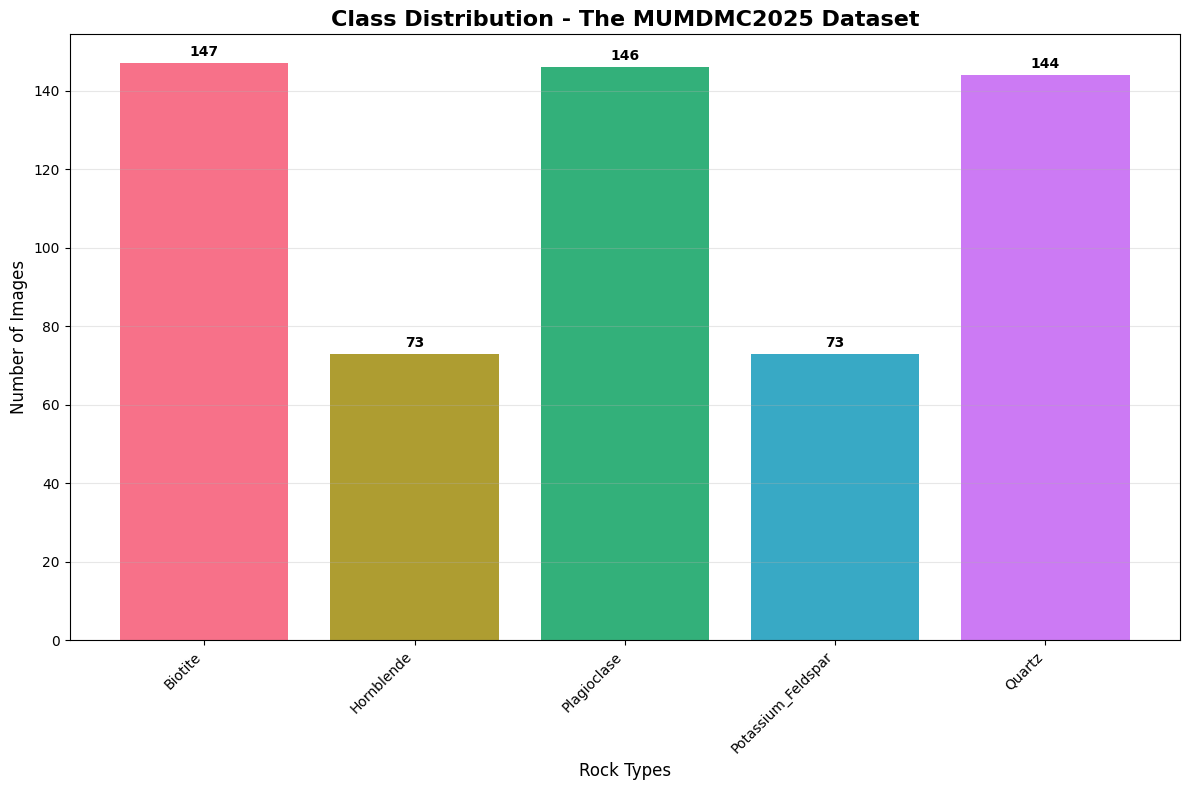

 Preprocessing data...
  Analyzing original image dimensions...
  Most common original size: (547, 500)
  Using standard size instead: (224, 224)
  Converting original images to features...
  Processing 583 images...
    Processed 500/583 images...
  Original images shape: (583, 150528)
  Converting resized images to features...
  Processing 583 images...
    Processed 500/583 images...
  Resized images shape: (583, 67500)
  Labels encoded: 5 classes
 Data preprocessing completed!
 Creating train-test split (80/20)...
Training set: 466 samples
Test set: 117 samples
 Train-test split completed!
 Training models...

 Training on Original images...
  Training DecisionTree...
    Training time: 32.61s
    Testing time: 0.01s
  Training KNN...
    Training time: 0.02s
    Testing time: 0.98s

 Training on Resized images...
  Training DecisionTree...
    Training time: 14.14s
    Testing time: 0.00s
  Training KNN...
    Training time: 0.01s
    Testing time: 0.41s
 Model training completed!

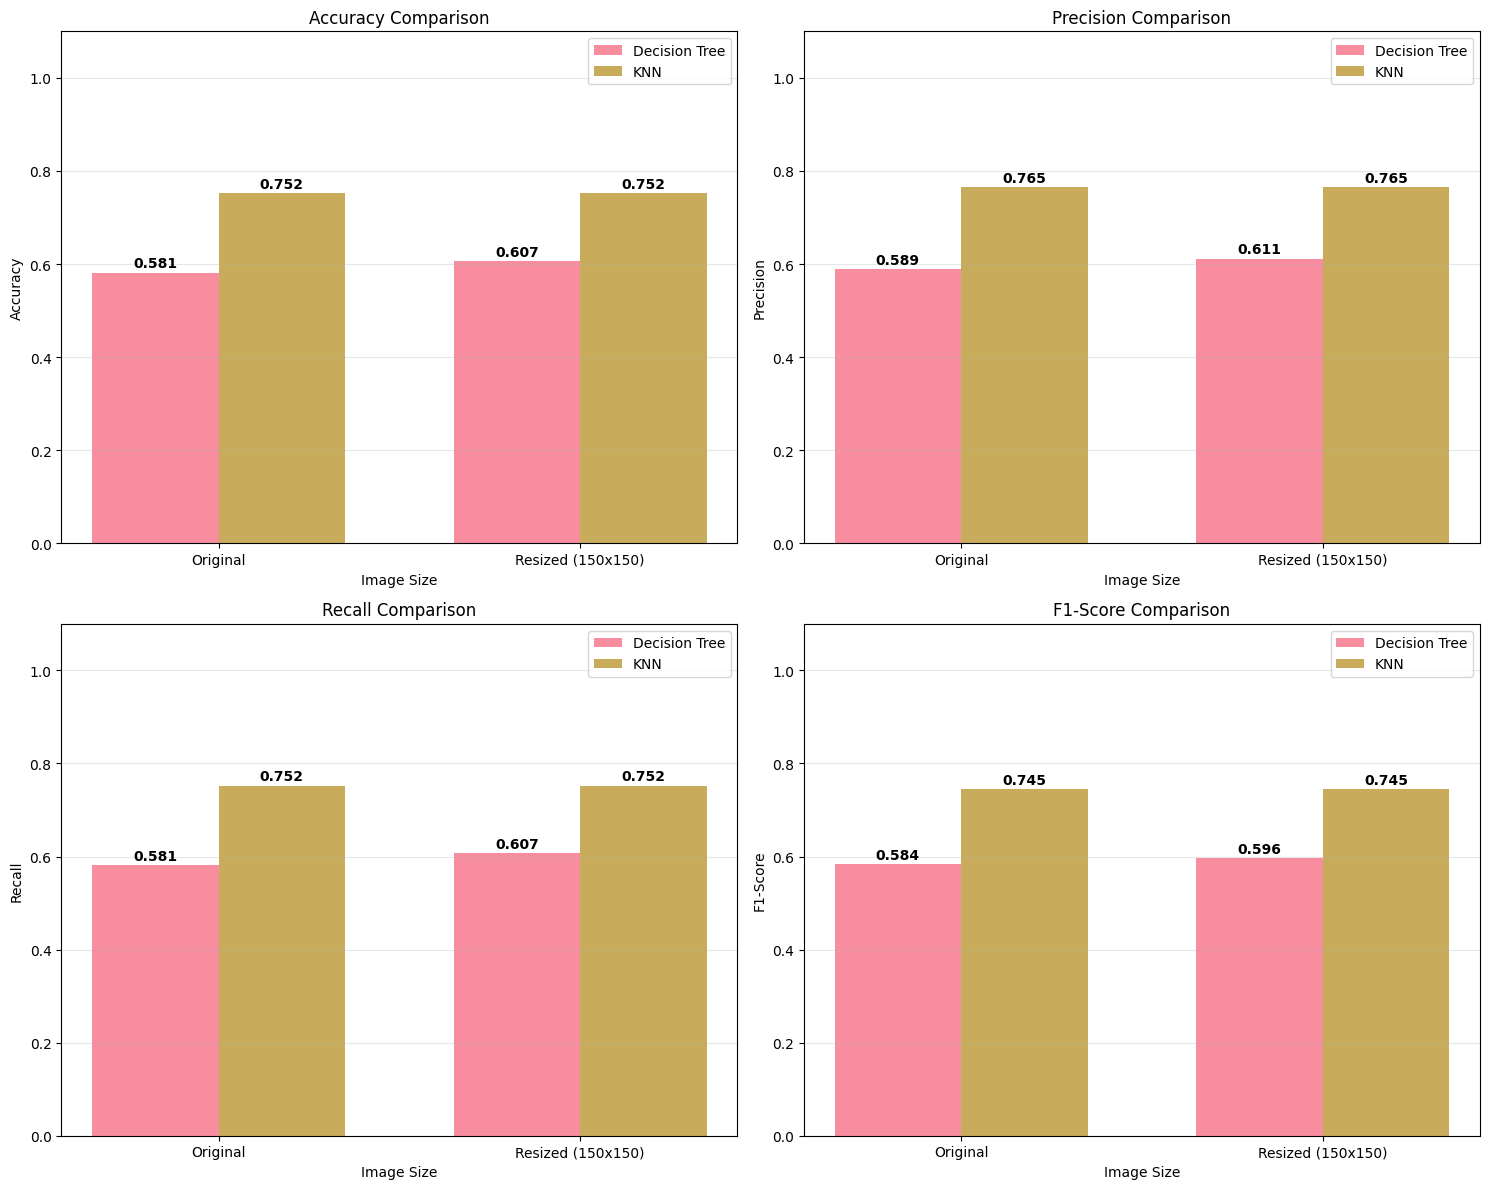

 Creating confusion matrices...


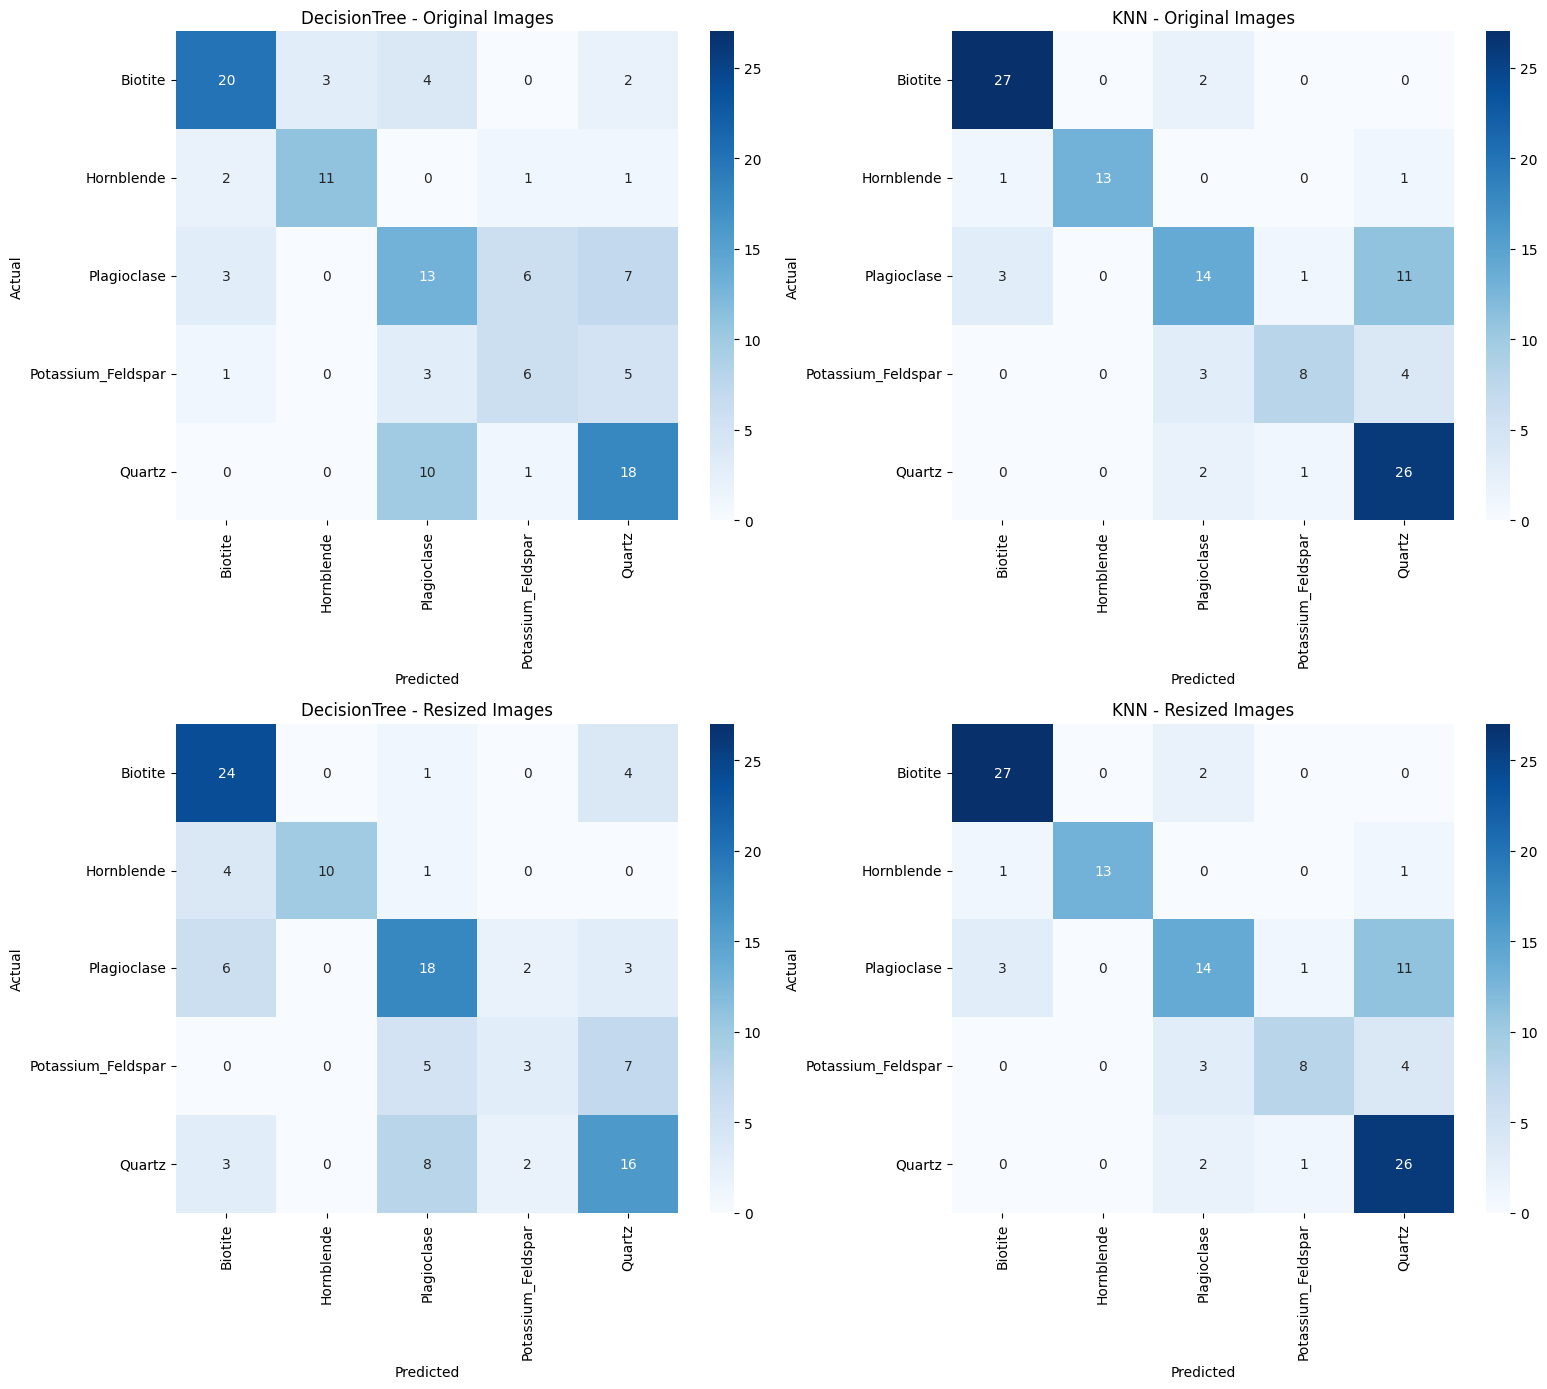

 Creating ROC-AUC curves...


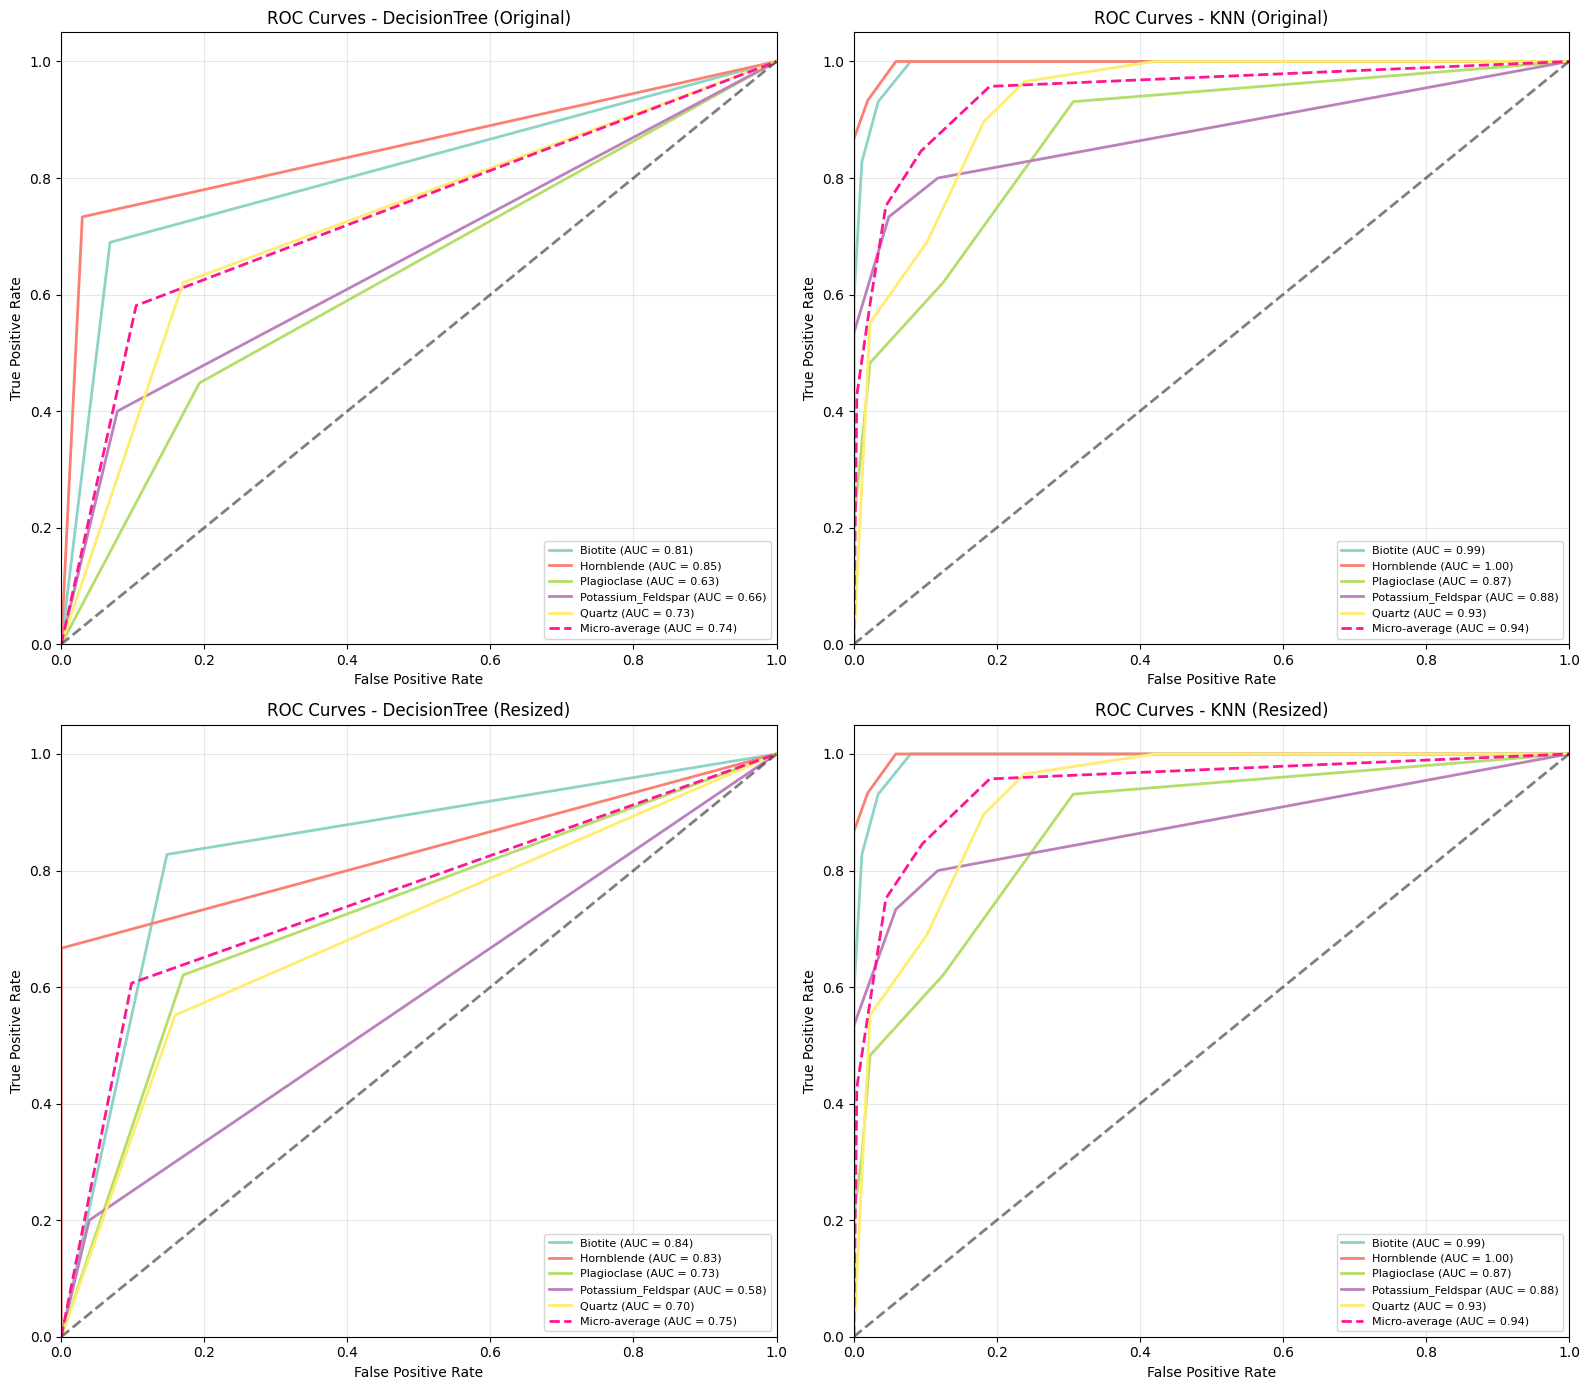

 ROC-AUC curves completed!
 Saving results to CSV files...
 Results saved to CSV files!
 Saving metadata to CSV...
 Metadata saved to CSV files!
 Creating sample images visualization...


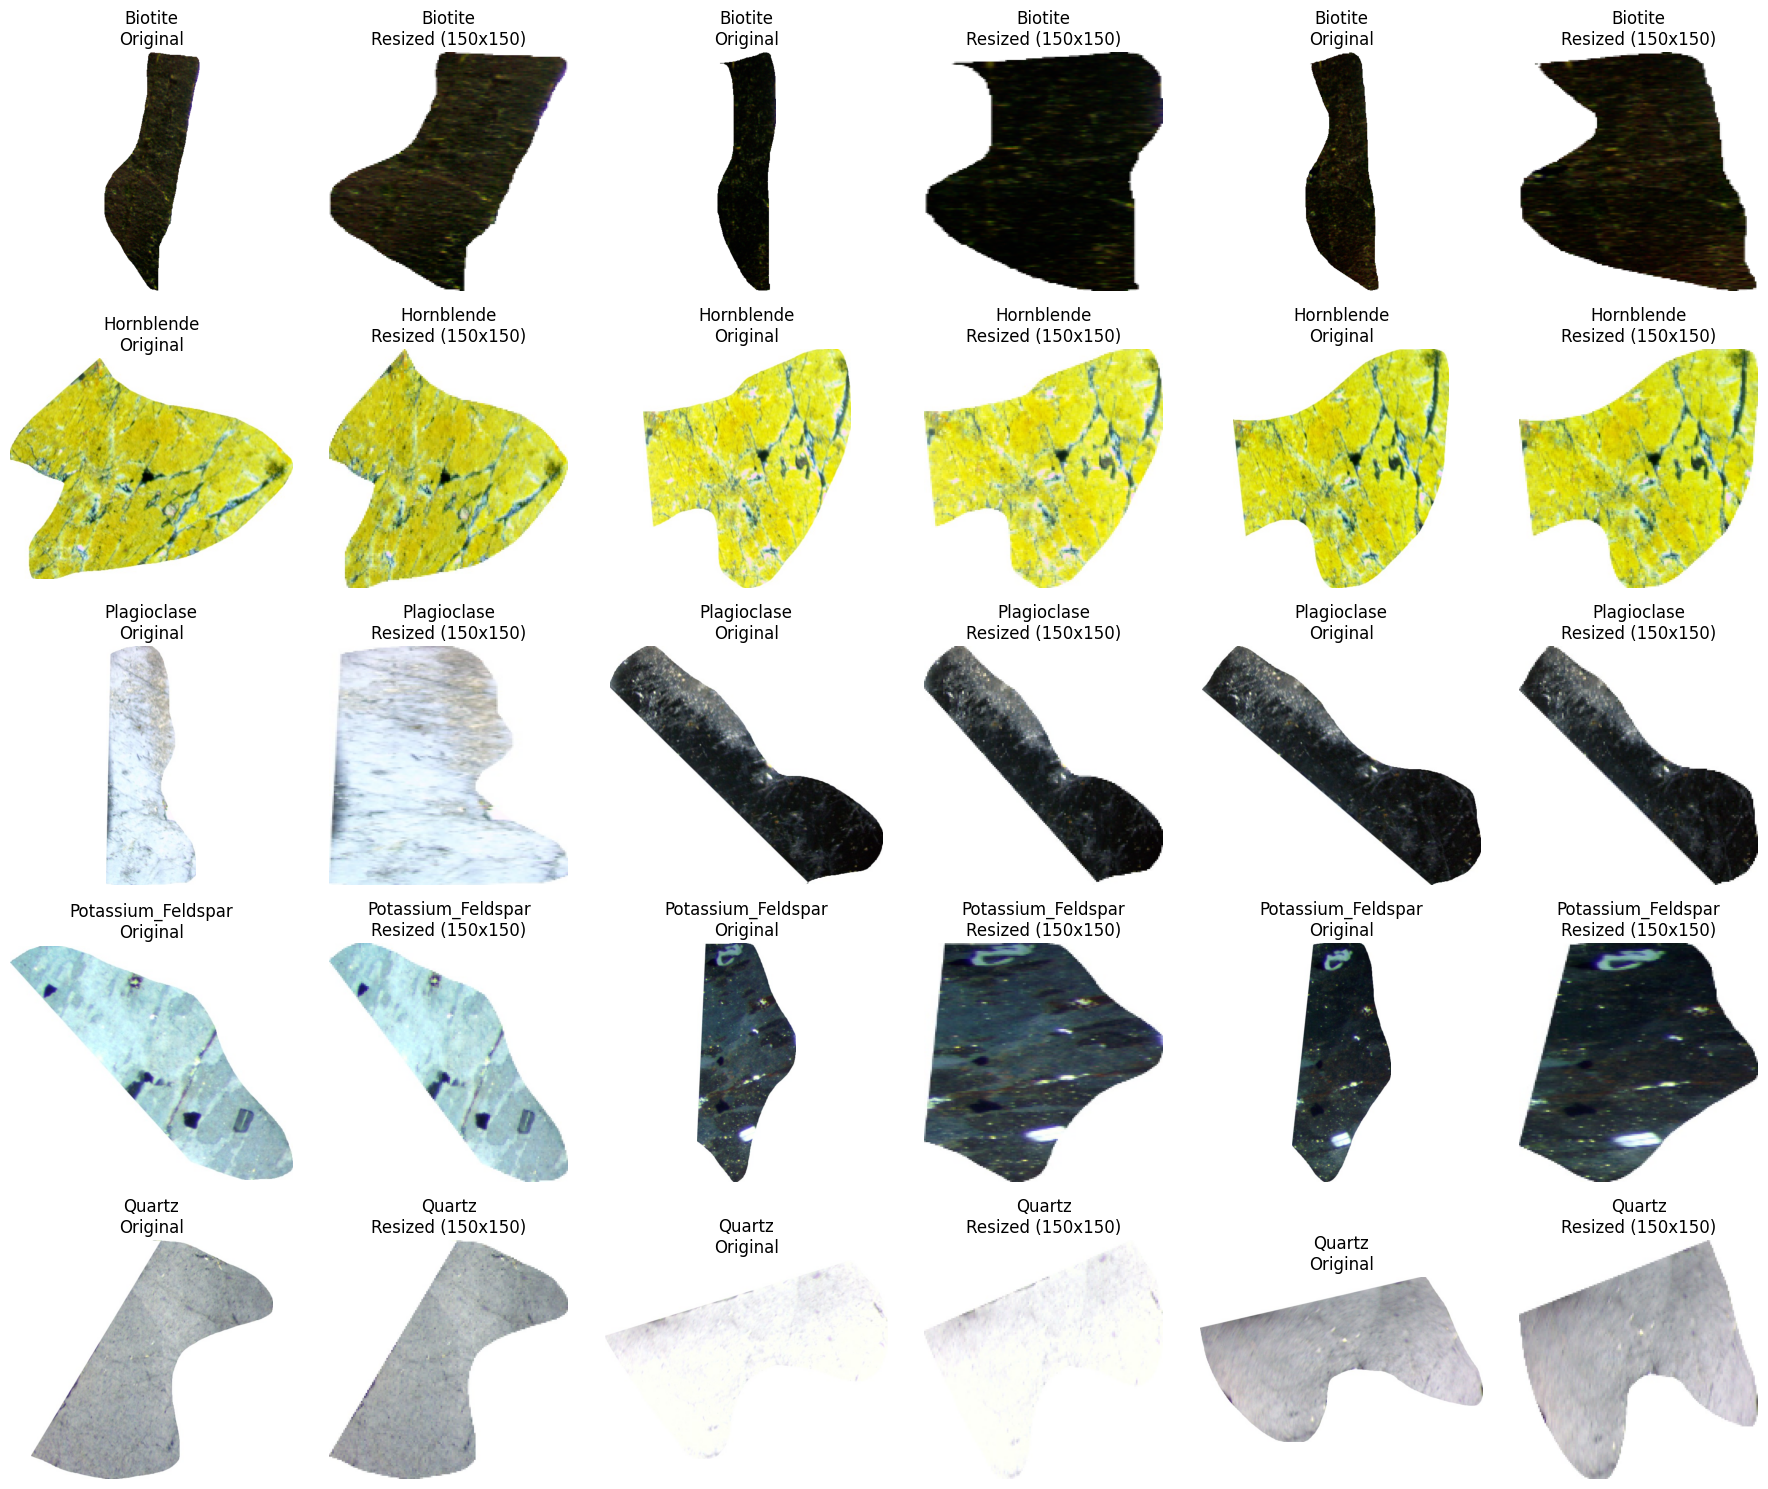


 Pipeline completed successfully!
 All outputs saved in '/content/outputs/' directory

 FINAL SUMMARY
Generated Files:
- class_distribution.png - Class distribution bar plot
- performance_metrics.png - Model performance comparison
- confusion_matrices.png - Confusion matrices for all models
- roc_curves.png - ROC-AUC curves for all models
- sample_images.png - Sample images before/after resize
- class_distribution.csv - Class counts
- performance_metrics.csv - All performance metrics
- confusion_matrices.csv - Confusion matrix data
- dataset_metadata.csv - Complete image metadata
- dataset_summary.csv - Dataset summary statistics

 Ready for download and analysis!


In [6]:
# Run the baseline
if __name__ == "__main__":
    # Use the extracted cropped-image folder
    dataset_path = "/content/MUMDMC2025_DataSet/Cropped_Images"
    pipeline = RockClassificationPipeline(dataset_path)

    # Fit and evaluate both models
    pipeline.run_complete_pipeline()

    # List saved outputs
    print("\n FINAL SUMMARY")
    print("="*40)
    print("Generated Files:")
    print("- class_distribution.png - Class distribution bar plot")
    print("- performance_metrics.png - Model performance comparison")
    print("- confusion_matrices.png - Confusion matrices for all models")
    print("- roc_curves.png - ROC-AUC curves for all models")
    print("- sample_images.png - Sample images before/after resize")
    print("- class_distribution.csv - Class counts")
    print("- performance_metrics.csv - All performance metrics")
    print("- confusion_matrices.csv - Confusion matrix data")
    print("- dataset_metadata.csv - Complete image metadata")
    print("- dataset_summary.csv - Dataset summary statistics")
    print("\n Ready for download and analysis!")

**Baseline interpretation.** The saved Colab run reports **75.2% KNN** and **60.7% Decision Tree** test accuracy on 150×150 images. These values are not directly comparable to the paper's results as an exact replication because the available subset is smaller and differently structured.

## Experiment 2 — Stratified 5-Fold Cross-Validation

**Objective.** Estimate how sensitive the baseline models are to different training/validation splits.

Run stratified five-fold cross-validation on **466 training images** at **150×150** resolution, with the original hyperparameters (`k=5` and unrestricted tree depth). Report the mean and standard deviation of Accuracy and Macro-F1. The 117-image test set is excluded from cross-validation; image-level folds can still share acquisition groups.

Results for each fold:
        Model  Fold  Accuracy  Macro_F1
Decision Tree     1     0.596     0.562
Decision Tree     2     0.624     0.619
Decision Tree     3     0.688     0.656
Decision Tree     4     0.634     0.650
Decision Tree     5     0.656     0.626
          KNN     1     0.755     0.759
          KNN     2     0.785     0.774
          KNN     3     0.656     0.641
          KNN     4     0.839     0.854
          KNN     5     0.742     0.746

Mean and standard deviation:
        Model  Accuracy_mean  Accuracy_std  Macro_F1_mean  Macro_F1_std
Decision Tree          0.640         0.035          0.623         0.037
          KNN          0.755         0.067          0.755         0.076


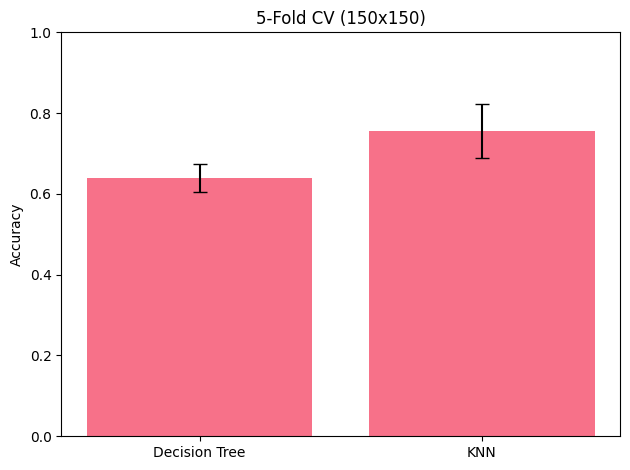

In [7]:
# Use the baseline training split (150x150)
X = pipeline.X_train_resized
y = pipeline.y_train

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

results = []

for model_name, model in models.items():
    for fold, (train_idx, val_idx) in enumerate(cv.split(X, y), start=1):
        model.fit(X[train_idx], y[train_idx])
        predictions = model.predict(X[val_idx])

        results.append({
            "Model": model_name,
            "Fold": fold,
            "Accuracy": accuracy_score(y[val_idx], predictions),
            "Macro_F1": f1_score(y[val_idx], predictions, average="macro")
        })

cv_results = pd.DataFrame(results)
cv_summary = cv_results.groupby("Model", as_index=False).agg(
    Accuracy_mean=("Accuracy", "mean"),
    Accuracy_std=("Accuracy", "std"),
    Macro_F1_mean=("Macro_F1", "mean"),
    Macro_F1_std=("Macro_F1", "std")
)

print("Results for each fold:")
print(cv_results.round(3).to_string(index=False))

print("\nMean and standard deviation:")
print(cv_summary.round(3).to_string(index=False))

cv_results.to_csv("/content/outputs/cv_fold_results.csv", index=False)
cv_summary.to_csv("/content/outputs/cv_summary.csv", index=False)

# Plot mean accuracy across folds
plt.bar(cv_summary["Model"], cv_summary["Accuracy_mean"],
        yerr=cv_summary["Accuracy_std"], capsize=5)
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("5-Fold CV (150x150)")
plt.tight_layout()
plt.savefig("/content/outputs/cv_accuracy.png", dpi=150)
plt.show()


**Interpretation.** Cross-validation assesses variability across image-level folds, not independent-crystal generalization. The saved run gives mean accuracy of **75.5%** for KNN and **64.0%** for Decision Tree.

## Experiment 3 — Hyperparameter Tuning

**Objective.** Test whether simple parameter choices improve classification on the same available subset.

Use stratified five-fold `GridSearchCV` on the **466 training images**. Compare KNN neighbors `[1, 3, 5, 7, 9]` and Decision Tree depths `[5, 10, 15, None]`, selecting configurations by **mean Macro-F1**. The test set is not used for parameter selection.

KNN: best {'n_neighbors': 1}, Macro-F1 = 0.886
Decision Tree: best {'max_depth': 10}, Macro-F1 = 0.623

Cross-validation results:
        Model   Parameter Value  CV_Accuracy  CV_Macro_F1
          KNN n_neighbors     1        0.891        0.886
          KNN n_neighbors     3        0.833        0.823
          KNN n_neighbors     5        0.755        0.755
          KNN n_neighbors     7        0.712        0.709
          KNN n_neighbors     9        0.689        0.676
Decision Tree   max_depth     5        0.592        0.578
Decision Tree   max_depth    10        0.640        0.623
Decision Tree   max_depth    15        0.640        0.623
Decision Tree   max_depth  None        0.640        0.623


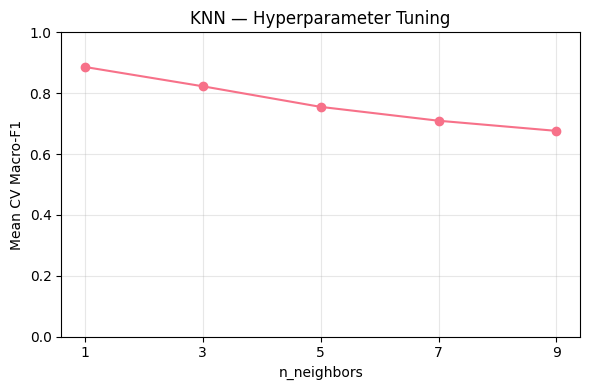

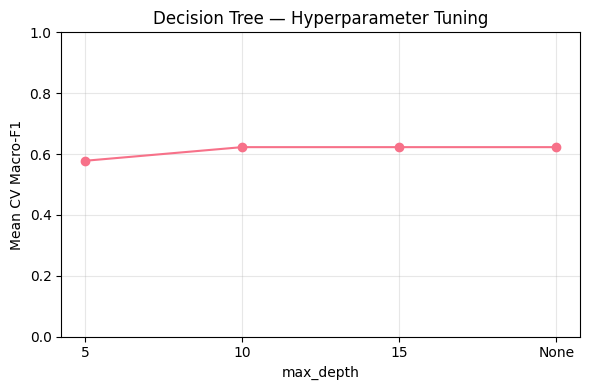

In [8]:
X = pipeline.X_train_resized
Y = pipeline.y_train
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define the parameter search
search_space = {
    "KNN": (KNeighborsClassifier(), {"n_neighbors": [1, 3, 5, 7, 9]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=42),
                      {"max_depth": [5, 10, 15, None]})
}

tuning_results = []
best_models = {}

for model_name, (model, parameters) in search_space.items():
    search = GridSearchCV(
        model,
        parameters,
        cv=cv,
        scoring={"Accuracy": "accuracy", "Macro_F1": "f1_macro"},
        refit="Macro_F1"
    )
    search.fit(X, Y)
    best_models[model_name] = search.best_estimator_

    parameter_name = list(parameters.keys())[0]
    for i, setting in enumerate(search.cv_results_["params"]):
        tuning_results.append({
            "Model": model_name,
            "Parameter": parameter_name,
            "Value": str(setting[parameter_name]),
            "CV_Accuracy": search.cv_results_["mean_test_Accuracy"][i],
            "CV_Macro_F1": search.cv_results_["mean_test_Macro_F1"][i]
        })

    print(f"{model_name}: best {search.best_params_}, Macro-F1 = {search.best_score_:.3f}")

tuning_results = pd.DataFrame(tuning_results)
print("\nCross-validation results:")
print(tuning_results.round(3).to_string(index=False))
tuning_results.to_csv("/content/outputs/tuning_results.csv", index=False)

# Plot cross-validated macro-F1
for model_name in search_space:
    rows = tuning_results[tuning_results["Model"] == model_name]
    plt.figure(figsize=(6, 4))
    plt.plot(rows["Value"], rows["CV_Macro_F1"], marker="o")
    plt.title(f"{model_name} — Hyperparameter Tuning")
    plt.xlabel(rows["Parameter"].iloc[0])
    plt.ylabel("Mean CV Macro-F1")
    plt.ylim(0, 1)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    name = model_name.lower().replace(" ", "_")
    plt.savefig(f"/content/outputs/tuning_{name}.png", dpi=150)
    plt.show()


### Evaluate the selected models

`GridSearchCV(refit="Macro_F1")` has already refitted the selected models on all **466 training images**. Evaluate them on the existing **117-image test set**. This is the same holdout used for the baseline, so it has been inspected across experiments.

In [9]:
final_results = []

for model_name, model in best_models.items():
    predictions = model.predict(pipeline.X_test_resized)
    final_results.append({
        "Model": model_name,
        "Test_Accuracy": accuracy_score(pipeline.y_test, predictions),
        "Test_Macro_F1": f1_score(pipeline.y_test, predictions, average="macro")
    })

final_results = pd.DataFrame(final_results)
print("Results on 117 test images:")
print(final_results.round(3).to_string(index=False))
final_results.to_csv("/content/outputs/tuned_test_results.csv", index=False)


Results on 117 test images:
        Model  Test_Accuracy  Test_Macro_F1
          KNN          0.872          0.870
Decision Tree          0.607          0.585


**Tuning interpretation.** In the saved run, the best KNN setting is **`k=1`**, giving **87.2% test accuracy**. A tree depth of `10` is selected, without a corresponding improvement in test accuracy. Parameter tuning demonstrates a gain on the existing image-level split; it does not remove overlap among acquisition groups.

## Experiment 4 — Error Analysis

**Objective.** Identify the most difficult mineral classes and examine the high score of KNN with `k=1`.

We perform three checks: confusion matrices for the tuned models, examples of KNN errors, and the closest training images for selected test examples. The latter check compares **parent folders**, not verified crystal identities.

### 4.1 Confusion matrices

Compare true and predicted classes for tuned KNN and Decision Tree, and report KNN precision, recall, and F1 by mineral.

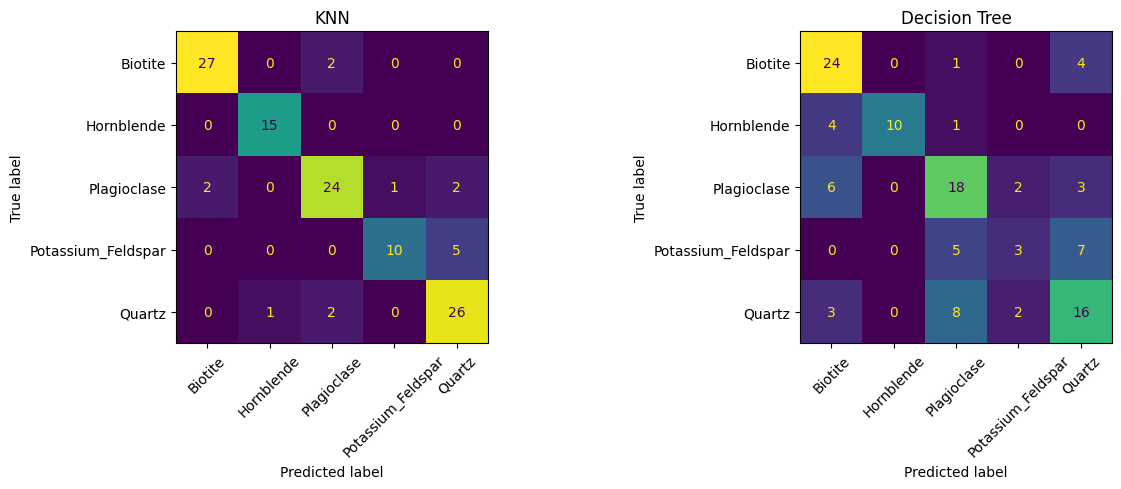

KNN classification report:
                    precision    recall  f1-score   support

           Biotite       0.93      0.93      0.93        29
        Hornblende       0.94      1.00      0.97        15
       Plagioclase       0.86      0.83      0.84        29
Potassium_Feldspar       0.91      0.67      0.77        15
            Quartz       0.79      0.90      0.84        29

          accuracy                           0.87       117
         macro avg       0.88      0.86      0.87       117
      weighted avg       0.88      0.87      0.87       117



In [10]:
class_names = pipeline.label_encoder.classes_
knn = best_models["KNN"]
knn_pred = knn.predict(pipeline.X_test_resized)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, model) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_predictions(
        pipeline.y_test, model.predict(pipeline.X_test_resized),
        display_labels=class_names, ax=ax, xticks_rotation=45,
        colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

print("KNN classification report:")
print(classification_report(pipeline.y_test, knn_pred, target_names=class_names))

### 4.2 Misclassified images

Show six photographs that tuned KNN assigned to the wrong mineral class. The figure contains examples of mistakes, not an independent validation experiment.

KNN mistakes: 15 / 117


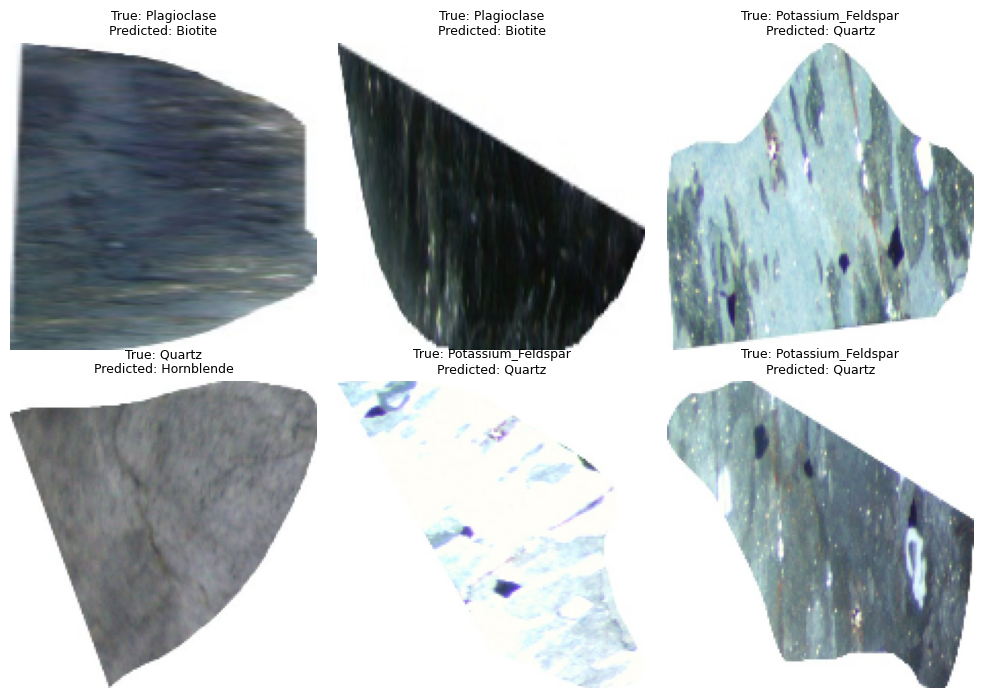

In [11]:
# Recover the baseline train/test indices.
train_ids, test_ids = train_test_split(
    np.arange(len(pipeline.metadata)), test_size=0.2,
    random_state=42, stratify=pipeline.y_encoded
)
wrong = np.where(knn_pred != pipeline.y_test)[0]
print(f"KNN mistakes: {len(wrong)} / {len(test_ids)}")

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, i in zip(axes.flat, wrong[:6]):
    ax.imshow(pipeline.images_resized[test_ids[i]])
    ax.set_title(f"True: {class_names[pipeline.y_test[i]]}\n"
                 f"Predicted: {class_names[knn_pred[i]]}", fontsize=9)
    ax.axis("off")
for ax in axes.flat[len(wrong[:6]):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 4.3 Nearest-neighbor and folder overlap

For each test image, find the closest training image using the tuned KNN. Count how often both images belong to the **same acquisition folder**, then display four example pairs. With `k=1`, selecting a neighbor from the same single-class folder necessarily gives the correct class; this highlights a limitation of the image-level split.

Nearest neighbor from same folder: 101/117
Same folder = True: 101/101 correct
Same folder = False: 1/16 correct


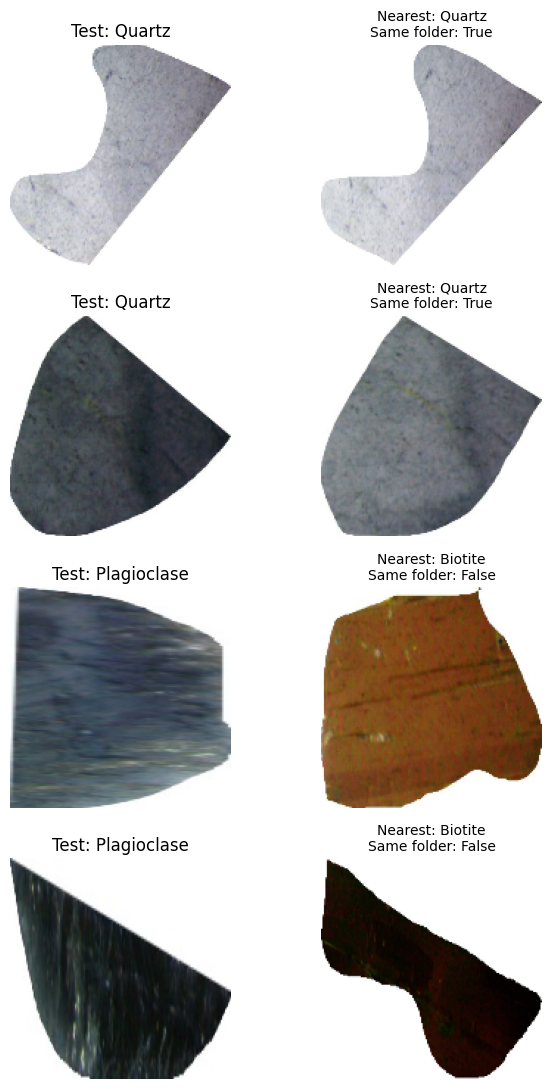

In [12]:
neighbor_ids = knn.kneighbors(pipeline.X_test_resized, n_neighbors=1,
                             return_distance=False)[:, 0]

# Treat each parent folder as an acquisition group, not a verified crystal.
same_group = np.array([
    Path(pipeline.metadata[test_ids[i]]["file_path"]).parent ==
    Path(pipeline.metadata[train_ids[j]]["file_path"]).parent
    for i, j in enumerate(neighbor_ids)
])
correct = knn_pred == pipeline.y_test
print(f"Nearest neighbor from same folder: {same_group.sum()}/{len(same_group)}")
for same in [True, False]:
    mask = same_group == same
    print(f"Same folder = {same}: {correct[mask].sum()}/{mask.sum()} correct")

# Show two correct and two incorrect predictions with their nearest neighbors.
examples = list(np.where(correct & same_group)[0][:2]) + list(wrong[:2])
fig, axes = plt.subplots(4, 2, figsize=(7, 11))
for row, i in enumerate(examples):
    axes[row, 0].imshow(pipeline.images_resized[test_ids[i]])
    axes[row, 1].imshow(pipeline.images_resized[train_ids[neighbor_ids[i]]])
    axes[row, 0].set_title(f"Test: {class_names[pipeline.y_test[i]]}")
    axes[row, 1].set_title(f"Nearest: {class_names[knn_pred[i]]}\n"
                           f"Same folder: {same_group[i]}", fontsize=10)
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()

**Experiment 4 interpretation.** In the saved run, KNN gets **102/117** test images correct. For **101/117** test images, the nearest training image is from the same acquisition folder. This indicates strong within-folder similarity; it does not prove memorization or quantify the impact on accuracy for unseen crystals.

**Metadata limitation.** The Excel metadata describes 2,500 images, but the working ZIP has 583. Repeated identifiers and filenames across different folders mean that the number of independent physical crystals is not verified. We treat eight folders as eight **acquisition groups**, potentially corresponding to distinct crystals based on preliminary visual inspection.

## Experiment 5 — CNN Transfer Learning

**Objective.** Compare the pixel-based Decision Tree/KNN models with two pretrained CNN architectures, **EfficientNet-B0** and **ConvNeXt-Tiny**. This extends beyond the original paper's classification methods.

**Data.** Use the same stratified 80/20 split as the baseline (**466 train / 117 test**), reserving 15% of the training portion for validation (**396 train / 70 validation**). CNN inputs are **224×224 RGB** normalized with ImageNet statistics. Random rotation, flips, and slight brightness/contrast jitter are applied **only during training**.

**Training stages.** First train a new five-class classification head with the pretrained backbone frozen (**10 epochs**, Adam, `lr=1e-3`). Then train the head and final backbone stage (**up to 15 epochs**, Adam, `lr=1e-5`, early stopping after five validation-loss checks without improvement). Both stages are evaluated on the same 117-image test set; the test set is not used for gradient updates. The repeated test evaluations should be reported transparently.

**Runtime.** A Colab GPU is strongly recommended. Pretrained CNN weights are downloaded at the first model construction.

### 5.1 CNN configuration

Fix the random seeds, choose the compute device, and define the image size, batch size, learning rates, training epochs, and output paths.

In [13]:
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE, "| torch", torch.__version__)
if DEVICE.type == "cpu":
    print("No GPU found. Training will be slow. In Colab: Runtime > Change runtime type > GPU")

OUT_DIR, MODEL_DIR = "/content/outputs", "/content/models"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

# Training configuration
IMG_SIZE      = 224
BATCH_SIZE    = 32
VAL_SIZE      = 0.15
HEAD_EPOCHS   = 10      # Linear probe
HEAD_LR       = 1e-3
FT_EPOCHS     = 15      # Fine-tuning
FT_LR         = 1e-5
PATIENCE      = 5       # Early stopping
NUM_WORKERS   = 2

Device: cuda | torch 2.11.0+cu130


### 5.2 Data split, transforms, and loaders

Recover the baseline train/test image indices, reserve a validation subset from training, and define augmentation and normalization. Display a few augmented samples to inspect the input pipeline.

Train: 396 | Val: 70 | Test: 117
  train {'Biotite': 100, 'Hornblende': 49, 'Plagioclase': 100, 'Potassium_Feldspar': 49, 'Quartz': 98}
  val   {'Biotite': 18, 'Hornblende': 9, 'Plagioclase': 17, 'Potassium_Feldspar': 9, 'Quartz': 17}
  test  {'Biotite': 29, 'Hornblende': 15, 'Plagioclase': 29, 'Potassium_Feldspar': 15, 'Quartz': 29}


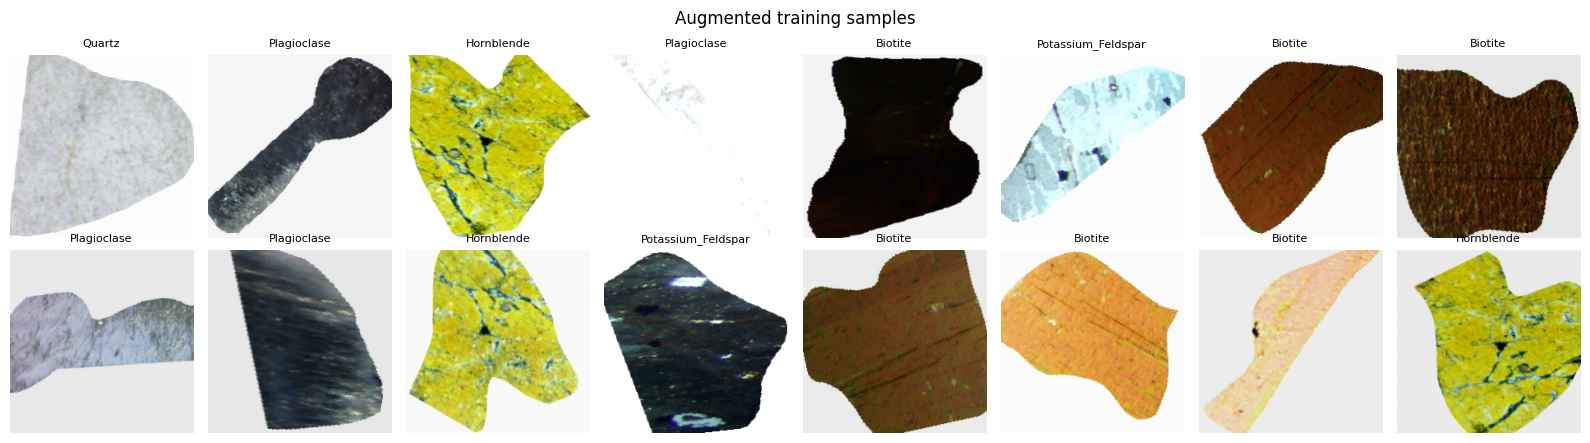

In [14]:
images      = pipeline.images_original          # Original RGB crops
y_all       = np.asarray(pipeline.y_encoded)
class_names = list(pipeline.label_encoder.classes_)
n_classes   = len(class_names)

# Reuse the baseline train/test split
all_idx = np.arange(len(y_all))
trainval_idx, test_idx = train_test_split(all_idx, test_size=0.2, random_state=42, stratify=y_all)
assert np.array_equal(y_all[test_idx], pipeline.y_test), "Test split differs from Experiment 1!"

# Reserve 15% of training for validation
train_idx, val_idx = train_test_split(trainval_idx, test_size=VAL_SIZE, random_state=42,
                                      stratify=y_all[trainval_idx])
print(f"Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}")
for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    print(f"  {name:5s}", {str(c): int(n) for c, n in zip(class_names, np.bincount(y_all[idx], minlength=n_classes))})

IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(180, fill=(255, 255, 255)),   # White crop background
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),   # Preserve hue and saturation
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class MineralDataset(Dataset):
    def __init__(self, idx, transform):
        self.idx, self.transform = list(idx), transform
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        img = Image.fromarray(images[j])          # RGB images from the baseline
        return self.transform(img), int(y_all[j])

def make_loader(idx, transform, shuffle):
    g = torch.Generator()
    g.manual_seed(SEED)
    return DataLoader(MineralDataset(idx, transform), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"), generator=g)

train_loader = make_loader(train_idx, train_tf, shuffle=True)
val_loader   = make_loader(val_idx,   eval_tf,  shuffle=False)
test_loader  = make_loader(test_idx,  eval_tf,  shuffle=False)

# Display augmented training samples
xb, yb = next(iter(train_loader))
mean, std = torch.tensor(IMAGENET_MEAN).view(3,1,1), torch.tensor(IMAGENET_STD).view(3,1,1)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, x, y in zip(axes.ravel(), xb[:16], yb[:16]):
    ax.imshow((x * std + mean).clamp(0, 1).permute(1, 2, 0).numpy())
    ax.set_title(class_names[y], fontsize=8)
    ax.axis("off")
plt.suptitle("Augmented training samples")
plt.tight_layout()
plt.show()

### 5.3 Models and training routines

Construct each pretrained CNN with a five-class head. Define training, validation, prediction, and metric calculations. The original training settings and update steps are unchanged.

In [15]:
def build_model(name):
    """Create an ImageNet backbone with a five-class head."""
    if name == "EfficientNet-B0":
        m = torchvision_models.efficientnet_b0(weights=torchvision_models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)   # Five mineral classes
        head, last_stage = m.classifier, [m.features[-2], m.features[-1]]
    elif name == "ConvNeXt-Tiny":
        m = torchvision_models.convnext_tiny(weights=torchvision_models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        m.classifier[2] = nn.Linear(m.classifier[2].in_features, n_classes)   # Five mineral classes
        head, last_stage = m.classifier, [m.features[-1]]
    else:
        raise ValueError(name)
    return m.to(DEVICE), head, last_stage

def set_trainable(model, modules):
    """Train only the selected modules."""
    for p in model.parameters():
        p.requires_grad = False
    for mod in modules:
        for p in mod.parameters():
            p.requires_grad = True
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    print(f"    trainable params: {n_train:,} / {n_total:,} ({100*n_train/n_total:.1f}%)")

def train_mode(model):
    """Keep frozen BatchNorm statistics unchanged during training."""
    model.train()
    for mod in model.modules():
        if isinstance(mod, nn.BatchNorm2d) and not any(p.requires_grad for p in mod.parameters()):
            mod.eval()

@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        logits = model(x.to(DEVICE, non_blocking=True))
        probs.append(torch.softmax(logits, 1).cpu())
        ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def run_stage(model, optimizer, epochs, stage, patience=None):
    """Train and restore weights from the best validation epoch."""
    criterion = nn.CrossEntropyLoss()
    best_loss, best_state, bad_epochs, history = np.inf, None, 0, []
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        train_mode(model)
        tr_loss, tr_correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * len(y)
            tr_correct += (out.argmax(1) == y).sum().item()
            n += len(y)
        p_val, y_val = predict(model, val_loader)
        val_loss = nn.functional.nll_loss(torch.log(torch.tensor(p_val) + 1e-12), torch.tensor(y_val)).item()
        val_acc = (p_val.argmax(1) == y_val).mean()
        history.append(dict(stage=stage, epoch=epoch, train_loss=tr_loss/n, train_acc=tr_correct/n,
                            val_loss=val_loss, val_acc=val_acc))
        improved = val_loss < best_loss - 1e-4
        if improved:
            best_loss, best_state, bad_epochs = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
        print(f"    [{stage}] epoch {epoch:2d}/{epochs}  train_loss {tr_loss/n:.3f}  train_acc {tr_correct/n:.3f}"
              f"  |  val_loss {val_loss:.3f}  val_acc {val_acc:.3f}{'  *' if improved else ''}")
        if patience is not None and bad_epochs >= patience:
            print(f"    early stopping (no val-loss improvement for {patience} epochs)")
            break
    model.load_state_dict(best_state)
    return time.time() - t0, history

def evaluate(model, model_name, mode, train_time):
    t0 = time.time()
    probs, y_true = predict(model, test_loader)
    test_time = time.time() - t0
    y_pred = probs.argmax(1)
    res = dict(Model=model_name, Mode=mode,
               Accuracy=accuracy_score(y_true, y_pred),
               Precision=precision_score(y_true, y_pred, average="weighted", zero_division=0),
               Recall=recall_score(y_true, y_pred, average="weighted", zero_division=0),
               F1_Score=f1_score(y_true, y_pred, average="weighted", zero_division=0),
               Macro_F1=f1_score(y_true, y_pred, average="macro", zero_division=0),
               ROC_AUC=roc_auc_score(y_true, probs, multi_class="ovr", average="macro"),
               Training_Time=train_time, Testing_Time=test_time)
    print(f"   TEST {model_name} [{mode}]: acc {res['Accuracy']:.3f} | F1(w) {res['F1_Score']:.3f}"
          f" | macro-F1 {res['Macro_F1']:.3f} | AUC {res['ROC_AUC']:.3f}")
    return res, dict(y_true=y_true, y_pred=y_pred, probs=probs)

### 5.4 Train and evaluate CNN models

For each architecture, train the classification head, fine-tune the last backbone stage, evaluate both checkpoints on the existing test set, and save model weights and training histories.

In [16]:
MODEL_NAMES = ["EfficientNet-B0", "ConvNeXt-Tiny"]
cnn_results, cnn_preds, cnn_history = [], {}, []

for model_name in MODEL_NAMES:
    print("\n" + "=" * 70 + f"\n {model_name}\n" + "=" * 70)
    set_seed()
    model, head, last_stage = build_model(model_name)

    # Stage 1: train the classification head
    print("  Stage 1: linear probe (backbone frozen)")
    set_trainable(model, [head])
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=HEAD_LR)
    t_head, hist = run_stage(model, opt, HEAD_EPOCHS, stage="head")
    cnn_history += [dict(Model=model_name, **h) for h in hist]
    res, pred = evaluate(model, model_name, "Head only", t_head)
    cnn_results.append(res)
    cnn_preds[(model_name, "Head only")] = pred
    torch.save(model.state_dict(), f"{MODEL_DIR}/{model_name}_head_only.pt")

    # Stage 2: fine-tune the head and last backbone stage
    print("  Stage 2: fine-tuning (head + last backbone stage)")
    set_trainable(model, [head] + last_stage)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=FT_LR)
    t_ft, hist = run_stage(model, opt, FT_EPOCHS, stage="finetune", patience=PATIENCE)
    cnn_history += [dict(Model=model_name, **h) for h in hist]
    res, pred = evaluate(model, model_name, "Fine-tuned", t_head + t_ft)   # Both training stages
    cnn_results.append(res)
    cnn_preds[(model_name, "Fine-tuned")] = pred
    torch.save(model.state_dict(), f"{MODEL_DIR}/{model_name}_finetuned.pt")

    del model, opt
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

print("\n Experiment 5 finished")


 EfficientNet-B0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 145MB/s]


  Stage 1: linear probe (backbone frozen)
    trainable params: 6,405 / 4,013,953 (0.2%)
    [head] epoch  1/10  train_loss 1.216  train_acc 0.621  |  val_loss 0.783  val_acc 0.886  *
    [head] epoch  2/10  train_loss 0.585  train_acc 0.939  |  val_loss 0.437  val_acc 0.957  *
    [head] epoch  3/10  train_loss 0.336  train_acc 0.980  |  val_loss 0.288  val_acc 0.986  *
    [head] epoch  4/10  train_loss 0.227  train_acc 0.992  |  val_loss 0.221  val_acc 0.971  *
    [head] epoch  5/10  train_loss 0.167  train_acc 0.992  |  val_loss 0.184  val_acc 0.971  *
    [head] epoch  6/10  train_loss 0.145  train_acc 0.987  |  val_loss 0.156  val_acc 0.986  *
    [head] epoch  7/10  train_loss 0.107  train_acc 0.990  |  val_loss 0.130  val_acc 1.000  *
    [head] epoch  8/10  train_loss 0.096  train_acc 0.995  |  val_loss 0.119  val_acc 1.000  *
    [head] epoch  9/10  train_loss 0.090  train_acc 0.992  |  val_loss 0.108  val_acc 1.000  *
    [head] epoch 10/10  train_loss 0.083  train_acc 0.99

100%|██████████| 109M/109M [00:00<00:00, 155MB/s]


  Stage 1: linear probe (backbone frozen)
    trainable params: 5,381 / 27,823,973 (0.0%)
    [head] epoch  1/10  train_loss 1.317  train_acc 0.503  |  val_loss 0.854  val_acc 0.886  *
    [head] epoch  2/10  train_loss 0.639  train_acc 0.932  |  val_loss 0.459  val_acc 0.957  *
    [head] epoch  3/10  train_loss 0.370  train_acc 0.975  |  val_loss 0.271  val_acc 0.986  *
    [head] epoch  4/10  train_loss 0.234  train_acc 0.985  |  val_loss 0.199  val_acc 0.986  *
    [head] epoch  5/10  train_loss 0.176  train_acc 0.987  |  val_loss 0.149  val_acc 1.000  *
    [head] epoch  6/10  train_loss 0.127  train_acc 0.990  |  val_loss 0.116  val_acc 1.000  *
    [head] epoch  7/10  train_loss 0.116  train_acc 0.992  |  val_loss 0.092  val_acc 1.000  *
    [head] epoch  8/10  train_loss 0.095  train_acc 0.995  |  val_loss 0.081  val_acc 1.000  *
    [head] epoch  9/10  train_loss 0.078  train_acc 0.997  |  val_loss 0.072  val_acc 1.000  *
    [head] epoch 10/10  train_loss 0.070  train_acc 0.9

### 5.5 Model comparison

Combine the baseline Decision Tree/KNN results with CNN metrics. Save the comparison table and print per-class classification reports.

In [17]:
rows = []
for ds_name, ds_label in [("Original", "224×224"), ("Resized", "150×150")]:
    for m_name, m in pipeline.metrics_results[ds_name].items():
        yp = pipeline.trained_models[ds_name][m_name]["predictions"]
        rows.append(dict(Model=m_name, Mode=f"Raw pixels {ds_label}",
                         Accuracy=m["accuracy"], Precision=m["precision"], Recall=m["recall"],
                         F1_Score=m["f1_score"],
                         Macro_F1=f1_score(pipeline.y_test, yp, average="macro"),
                         ROC_AUC=np.nan,
                         Training_Time=m["training_time"], Testing_Time=m["testing_time"]))
comparison = pd.concat([pd.DataFrame(rows), pd.DataFrame(cnn_results)], ignore_index=True)

pd.set_option("display.precision", 3)
display(comparison)

pd.DataFrame(cnn_results).to_csv(f"{OUT_DIR}/cnn_performance_metrics.csv", index=False)
comparison.to_csv(f"{OUT_DIR}/all_models_comparison.csv", index=False)
pd.DataFrame(cnn_history).to_csv(f"{OUT_DIR}/cnn_training_history.csv", index=False)

for (m_name, mode), p in cnn_preds.items():
    print(f"\n{m_name} [{mode}]")
    print(classification_report(p["y_true"], p["y_pred"], target_names=class_names, digits=3))

,Model,Mode,Accuracy,Precision,Recall,F1_Score,Macro_F1,ROC_AUC,Training_Time,Testing_Time
0,DecisionTree,Raw pixels 224×224,0.581,0.589,0.581,0.584,0.584,NaN,32.612,0.006
1,KNN,Raw pixels 224×224,0.752,0.765,0.752,0.745,0.752,NaN,0.025,0.983
2,DecisionTree,Raw pixels 150×150,0.607,0.611,0.607,0.596,0.585,NaN,14.142,0.003
3,KNN,Raw pixels 150×150,0.752,0.765,0.752,0.745,0.752,NaN,0.011,0.409
4,EfficientNet-B0,Head only,0.966,0.970,0.966,0.966,0.966,1.0,24.564,0.505
5,EfficientNet-B0,Fine-tuned,0.991,0.992,0.991,0.991,0.993,1.0,37.660,0.486
6,ConvNeXt-Tiny,Head only,1.000,1.000,1.000,1.000,1.000,1.0,28.694,0.751
7,ConvNeXt-Tiny,Fine-tuned,1.000,1.000,1.000,1.000,1.000,1.0,75.059,0.760



EfficientNet-B0 [Head only]
                    precision    recall  f1-score   support

           Biotite      1.000     0.966     0.982        29
        Hornblende      1.000     1.000     1.000        15
       Plagioclase      1.000     0.966     0.982        29
Potassium_Feldspar      1.000     0.867     0.929        15
            Quartz      0.879     1.000     0.935        29

          accuracy                          0.966       117
         macro avg      0.976     0.960     0.966       117
      weighted avg      0.970     0.966     0.966       117


EfficientNet-B0 [Fine-tuned]
                    precision    recall  f1-score   support

           Biotite      1.000     1.000     1.000        29
        Hornblende      1.000     1.000     1.000        15
       Plagioclase      1.000     0.966     0.982        29
Potassium_Feldspar      1.000     1.000     1.000        15
            Quartz      0.967     1.000     0.983        29

          accuracy                  

### 5.6 CNN diagnostics

Plot training and validation curves, compare metrics, and show confusion matrices and one-vs-rest ROC curves for both architectures and both training stages.

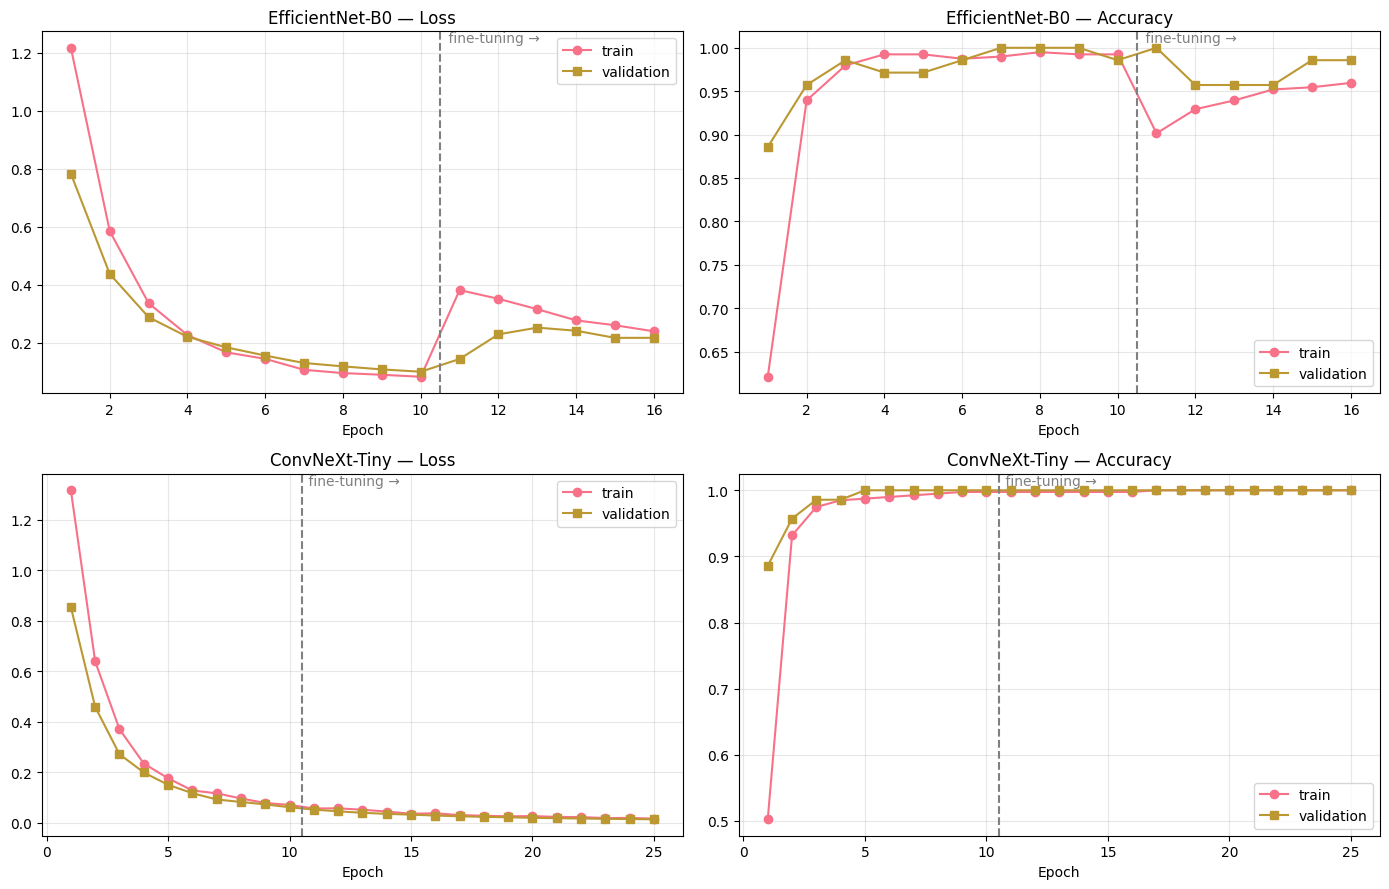

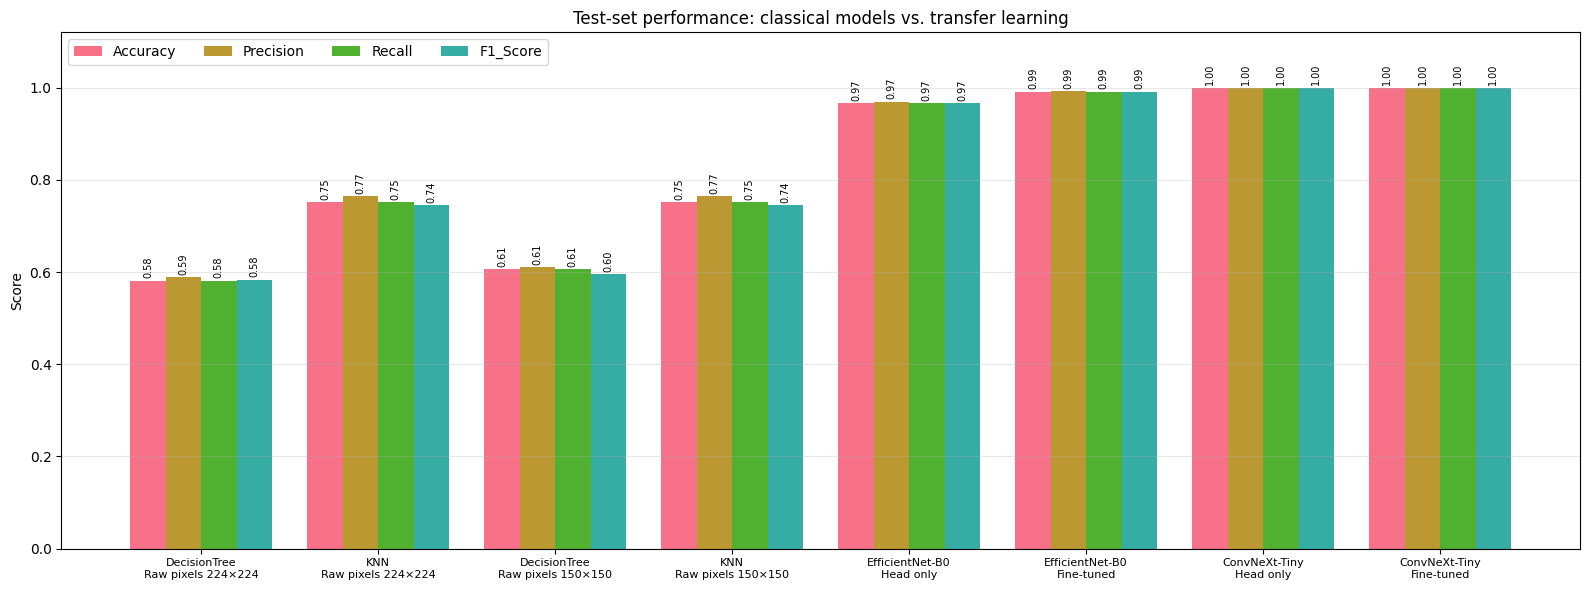

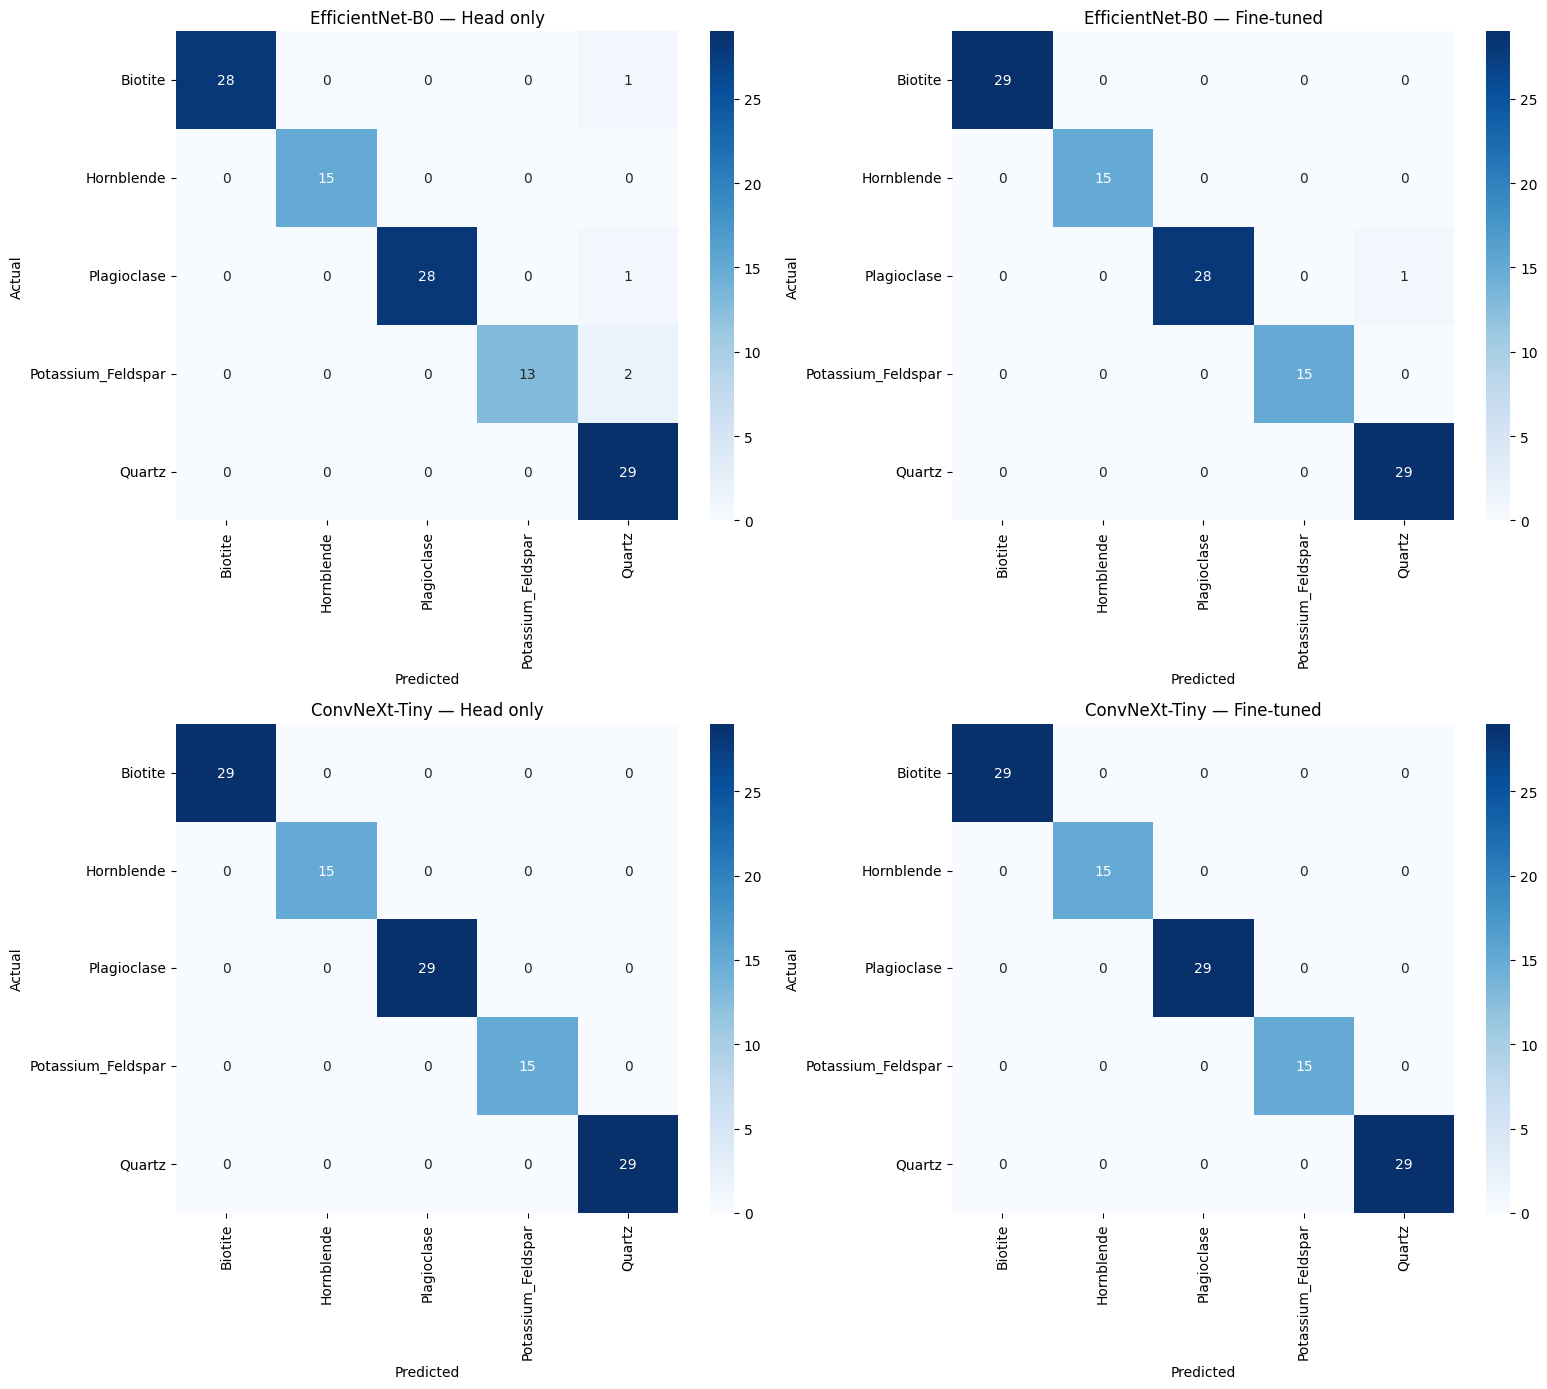

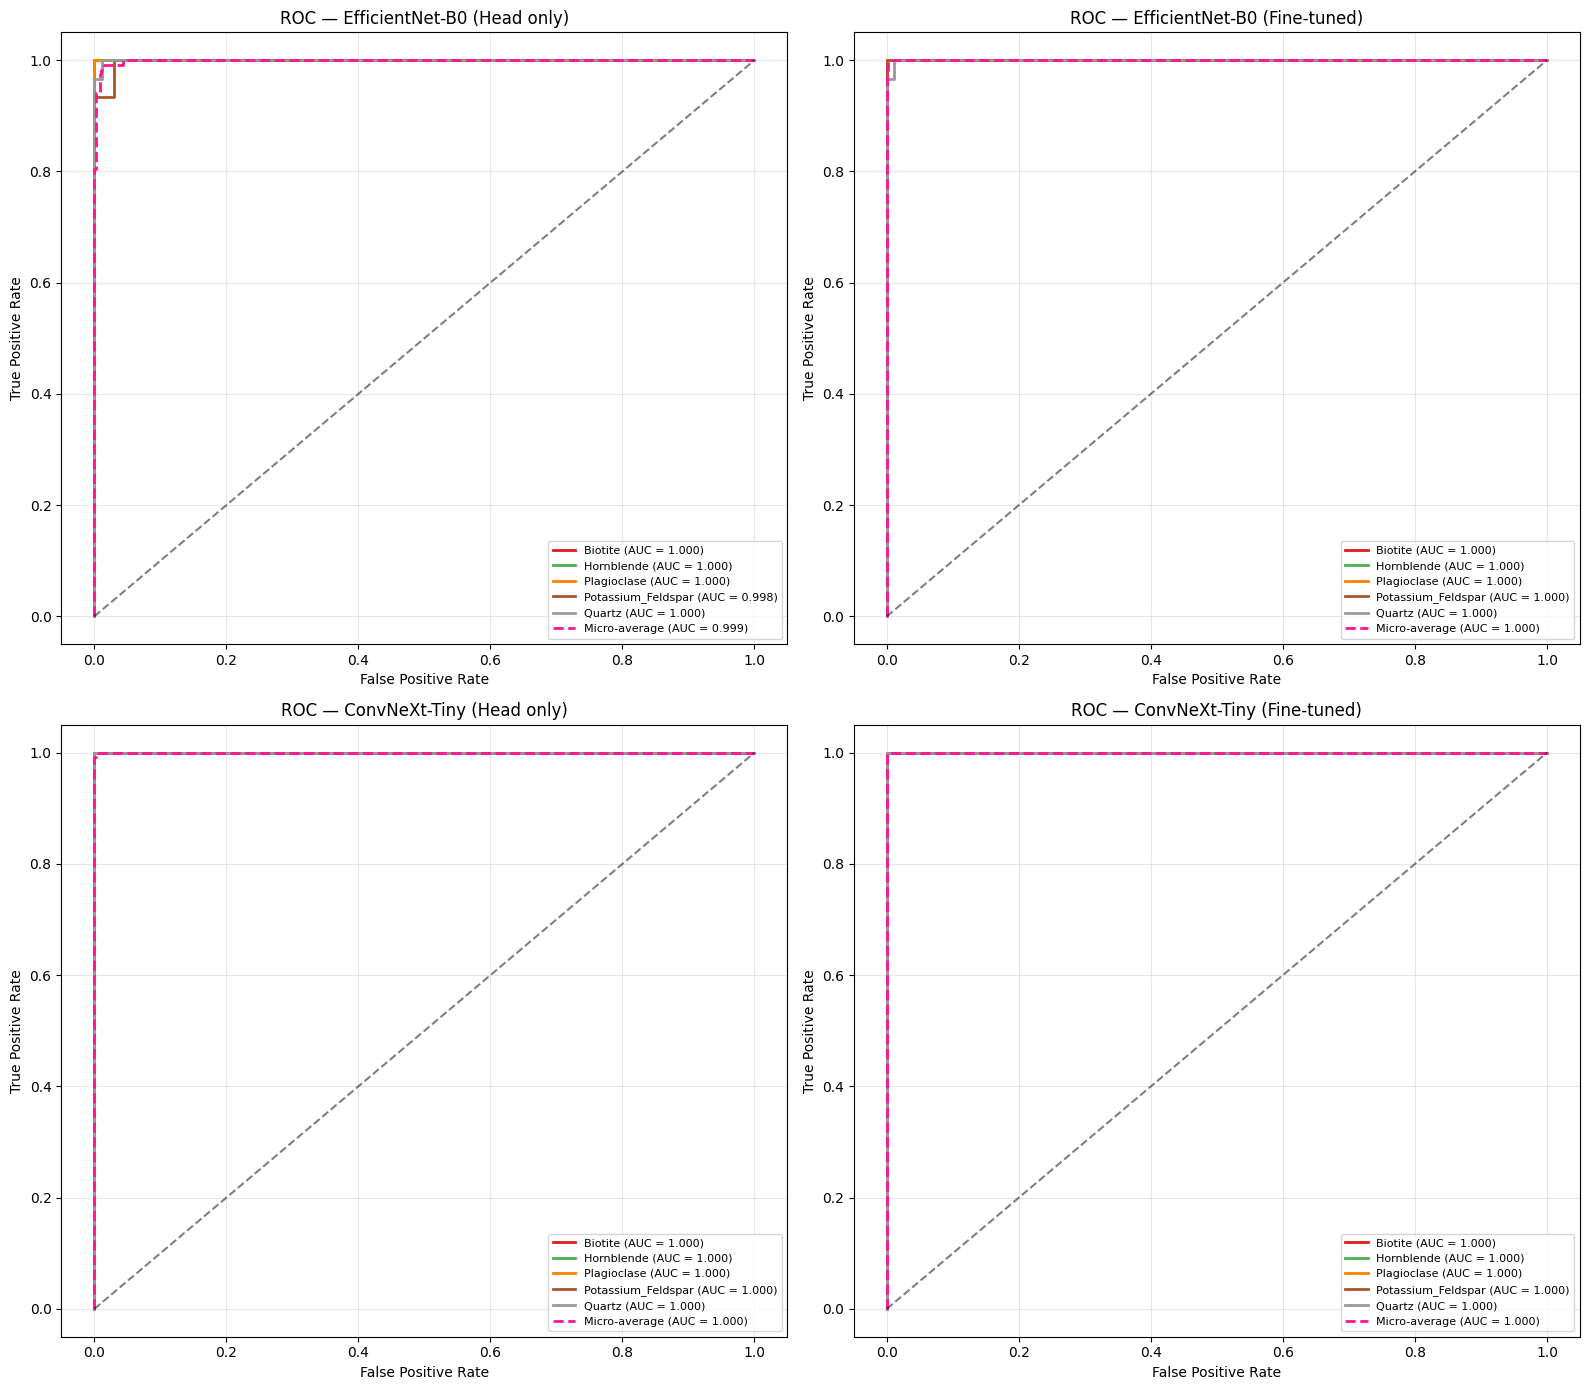

Saved to /content/outputs : ['all_models_comparison.csv', 'all_models_metrics.png', 'cnn_confusion_matrices.png', 'cnn_learning_curves.png', 'cnn_performance_metrics.csv', 'cnn_roc_curves.png', 'cnn_training_history.csv']


In [18]:
hist = pd.DataFrame(cnn_history)

# Learning curves across both training stages
fig, axes = plt.subplots(len(MODEL_NAMES), 2, figsize=(14, 4.5 * len(MODEL_NAMES)), squeeze=False)
for r, m_name in enumerate(MODEL_NAMES):
    h = hist[hist.Model == m_name].reset_index(drop=True)
    x = np.arange(1, len(h) + 1)
    n_head = (h.stage == "head").sum()
    for c, (metric, title) in enumerate([("loss", "Loss"), ("acc", "Accuracy")]):
        ax = axes[r, c]
        ax.plot(x, h[f"train_{metric}"], "o-", label="train")
        ax.plot(x, h[f"val_{metric}"], "s-", label="validation")
        ax.axvline(n_head + 0.5, color="gray", ls="--")
        ax.text(n_head + 0.6, ax.get_ylim()[1], " fine-tuning →", va="top", color="gray")
        ax.set_title(f"{m_name} — {title}")
        ax.set_xlabel("Epoch")
        ax.grid(alpha=.3)
        ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/cnn_learning_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# Model metric comparison
plot_df = comparison.copy()
plot_df["Label"] = plot_df.Model + "\n" + plot_df.Mode
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1_Score"]
fig, ax = plt.subplots(figsize=(16, 6))
w = 0.2
xs = np.arange(len(plot_df))
for i, met in enumerate(metrics_to_plot):
    bars = ax.bar(xs + (i - 1.5) * w, plot_df[met], w, label=met)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005, f"{b.get_height():.2f}",
                ha="center", va="bottom", fontsize=7, rotation=90)
ax.set_xticks(xs)
ax.set_xticklabels(plot_df.Label, fontsize=8)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=.3)
ax.legend(ncol=4)
ax.set_title("Test-set performance: classical models vs. transfer learning")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/all_models_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

# CNN confusion matrices
keys = list(cnn_preds.keys())
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for ax, k in zip(axes.ravel(), keys):
    cm = confusion_matrix(cnn_preds[k]["y_true"], cnn_preds[k]["y_pred"], labels=range(n_classes))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set_title(f"{k[0]} — {k[1]}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/cnn_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

# One-vs-rest ROC curves
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
colors = plt.cm.Set1(np.linspace(0, 1, n_classes))
for ax, k in zip(axes.ravel(), keys):
    y_bin = label_binarize(cnn_preds[k]["y_true"], classes=range(n_classes))
    probs = cnn_preds[k]["probs"]
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
        ax.plot(fpr, tpr, color=colors[i], lw=2, label=f"{class_names[i]} (AUC = {auc(fpr, tpr):.3f})")
    fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
    ax.plot(fpr, tpr, "--", color="deeppink", lw=2, label=f"Micro-average (AUC = {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=.5)
    ax.set_title(f"ROC — {k[0]} ({k[1]})")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/cnn_roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved to", OUT_DIR, ":", sorted(f for f in os.listdir(OUT_DIR) if "cnn" in f or "all_models" in f))

**CNN interpretation.** In the saved run, fine-tuned EfficientNet-B0 reaches **99.1%** and ConvNeXt-Tiny reaches **100%** test accuracy. Both use ImageNet pretraining, and the existing test images share acquisition folders with training. These scores describe this particular split and must not be interpreted as verified performance on independent specimens.

## Conclusions and reproducibility notes

- **Methodological reproduction:** Decision Tree and KNN were trained on two input sizes following the classification approach reported in the reference paper, adapted to the available 583-image subset.
- **Validation and tuning:** Five-fold cross-validation and parameter search quantify variability and improve KNN on the image-level split.
- **Error analysis:** 101 of 117 KNN test images have their nearest neighbor in the same acquisition folder. This reveals strong within-folder similarity and limits claims about generalization to new crystals.
- **CNN extension:** EfficientNet-B0 and ConvNeXt-Tiny perform very well on the same test split, but use pretrained ImageNet features and do not provide independent-crystal validation.
- **Dataset documentation:** The accessible ZIP and the metadata workbooks differ in size and naming; eight folders may correspond to eight crystals, but physical independence is unconfirmed.

**To reproduce:** use the dependency list (`requirements.txt`), run the notebook top-to-bottom in Colab, retain `random_state=42`, and report the hardware and installed library versions. CNN training on GPU may vary slightly across hardware and library versions despite fixed seeds. Saved cell outputs reflect the previous Colab run; use freshly executed results when submitting new comparisons.

**Reference article:** https://doi.org/10.1038/s41597-025-05879-9  
**Authors' repository:** https://github.com/MscModelTrain/MUMDMC2025-preprocessing-evaluation  
**Dataset publication:** https://doi.org/10.6084/m9.figshare.29483204.v1